In [1]:
import os, glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 300

In [2]:
data_dir = r"D:\!Work\IFA\!data\Urban_fluxes_NE\processed"

sites = {'Moscow':{'tz':3, 'ds_name':''},
         'Tomsk':{'tz':7, 'ds_name':'new_py'},
         'Beijing':{'tz':8, 'ds_name':''}}

df4sites = {}

sites4city = {}

for city_name, city_info in sites.items():
    
    city_time_belt = city_info['tz']
    ds_name = city_info['ds_name']
    file_pattern = data_dir + '/' + city_name + ('_' if ds_name else '') + ds_name + '/L1/*.csv'

    display(file_pattern)


    files = [f for f in glob.glob(file_pattern) if 'ERA5' not in f and 'Beijing_8m' not in f]
        
    if city_name != 'Beijing':
        levels = np.array([float(file.split('_')[-1].split('.')[0].replace('m', '')) for file in files]) #)]
        levels_idx = np.argsort(levels)
        files_sorted = np.array(files)[levels_idx]
    else:
        files1 = [f for f in files if 'Beijing' in os.path.basename(f)]
        levels1 = np.array([float(file.split('_')[-1].split('.')[0].replace('m', '')) for file in files1])
        levels1_idx = np.argsort(levels1)

        
        files2 = [f for f in files if 'Xianghe' in os.path.basename(f)]
        levels2 = np.array([float(file.split('_')[-1].split('.')[0].replace('m', '')) for file in files2])
        levels2_idx = np.argsort(levels2)

        files_sorted = np.concatenate((np.array(files1)[levels1_idx], np.array(files2)[levels2_idx]))
        #files_sorted = np.vstack((np.array(files1)[levels1_idx], np.array(files1)[levels2_idx]))
        
    for file in files_sorted:
        
        site = os.path.basename(file).split('.')[0]
        print (file)
        df = pd.read_csv(file, index_col=0, parse_dates=True)
        df.index = df.index + pd.Timedelta(hours=city_time_belt)
        df4sites[city_name + '_' + site] = df

    print (f'{city_name}: {len(levels)} levels')
    
    for i in range (len(levels), 6):
        dummy_df = df.iloc[0:2] * np.nan
        dummy_df['qc_tot'] = 1
        df4sites[city_name + '_dummy_' + str(i)] = dummy_df# pd.DataFrame(index = df4sites[city_name + '_dummy_1'].index, columns = df4sites[city_name + '_dummy_1'].columns)

print (df4sites.keys())

'D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Moscow/L1/*.csv'

D:\!Work\IFA\!data\Urban_fluxes_NE\processed/Moscow/L1\MSU_2m.csv
D:\!Work\IFA\!data\Urban_fluxes_NE\processed/Moscow/L1\MSU_11m.csv
D:\!Work\IFA\!data\Urban_fluxes_NE\processed/Moscow/L1\MSU_19m.csv
D:\!Work\IFA\!data\Urban_fluxes_NE\processed/Moscow/L1\LOD_31m.csv
D:\!Work\IFA\!data\Urban_fluxes_NE\processed/Moscow/L1\ZNS_56m.csv
Moscow: 5 levels


'D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Tomsk_new_py/L1/*.csv'

D:\!Work\IFA\!data\Urban_fluxes_NE\processed/Tomsk_new_py/L1\Voronino_10m.csv
D:\!Work\IFA\!data\Urban_fluxes_NE\processed/Tomsk_new_py/L1\BEK_30m.csv
D:\!Work\IFA\!data\Urban_fluxes_NE\processed/Tomsk_new_py/L1\IMCESmezo_30m.csv
D:\!Work\IFA\!data\Urban_fluxes_NE\processed/Tomsk_new_py/L1\IMCES_30m.csv
D:\!Work\IFA\!data\Urban_fluxes_NE\processed/Tomsk_new_py/L1\Oblkom_30m.csv
D:\!Work\IFA\!data\Urban_fluxes_NE\processed/Tomsk_new_py/L1\IMCES_40m.csv
Tomsk: 6 levels


'D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Beijing/L1/*.csv'

D:\!Work\IFA\!data\Urban_fluxes_NE\processed/Beijing/L1\Beijing_16m.csv
D:\!Work\IFA\!data\Urban_fluxes_NE\processed/Beijing/L1\Beijing_47m.csv
D:\!Work\IFA\!data\Urban_fluxes_NE\processed/Beijing/L1\Beijing_80m.csv
D:\!Work\IFA\!data\Urban_fluxes_NE\processed/Beijing/L1\Beijing_140m.csv
D:\!Work\IFA\!data\Urban_fluxes_NE\processed/Beijing/L1\Beijing_200m.csv
D:\!Work\IFA\!data\Urban_fluxes_NE\processed/Beijing/L1\Beijing_280m.csv
D:\!Work\IFA\!data\Urban_fluxes_NE\processed/Beijing/L1\Xianghe_32m.csv
D:\!Work\IFA\!data\Urban_fluxes_NE\processed/Beijing/L1\Xianghe_80m.csv
Beijing: 6 levels
dict_keys(['Moscow_MSU_2m', 'Moscow_MSU_11m', 'Moscow_MSU_19m', 'Moscow_LOD_31m', 'Moscow_ZNS_56m', 'Moscow_dummy_5', 'Tomsk_Voronino_10m', 'Tomsk_BEK_30m', 'Tomsk_IMCESmezo_30m', 'Tomsk_IMCES_30m', 'Tomsk_Oblkom_30m', 'Tomsk_IMCES_40m', 'Beijing_Beijing_16m', 'Beijing_Beijing_47m', 'Beijing_Beijing_80m', 'Beijing_Beijing_140m', 'Beijing_Beijing_200m', 'Beijing_Beijing_280m', 'Beijing_Xianghe_32m', '

In [3]:
import seaborn as sns

df_merged = pd.DataFrame()

for site, df in df4sites.items():
    cur_df = df.loc[(df['qc_tot'] > 0) & (df['Wind_vel'] < 15) & (df['Ustar'] < 2), ['Wind_vel', 'Qtau', 'Ustar', 'Wind_W_std']]
    if 'Moscow_LOD' in site:
        df4sites[site] = df4sites[site]['2022-06-01':]
        #df4sites[site] = df4sites[site][:'2022-01-01']
    # elif 'Voronino' in site:
    #     df4sites[site] = df4sites[site]['2025-06-01':]
    # elif 'Oblkom' in site:
    #     df4sites[site] = df4sites[site]['2024-08-01':]
    
    if cur_df.shape[0] == 0:
        cur_df = df_merged.iloc[0:2].drop(columns=['site']) * np.nan
    cur_df.loc[:, 'site'] = site
    

        
    df_merged = pd.concat([df_merged, cur_df], axis=0)


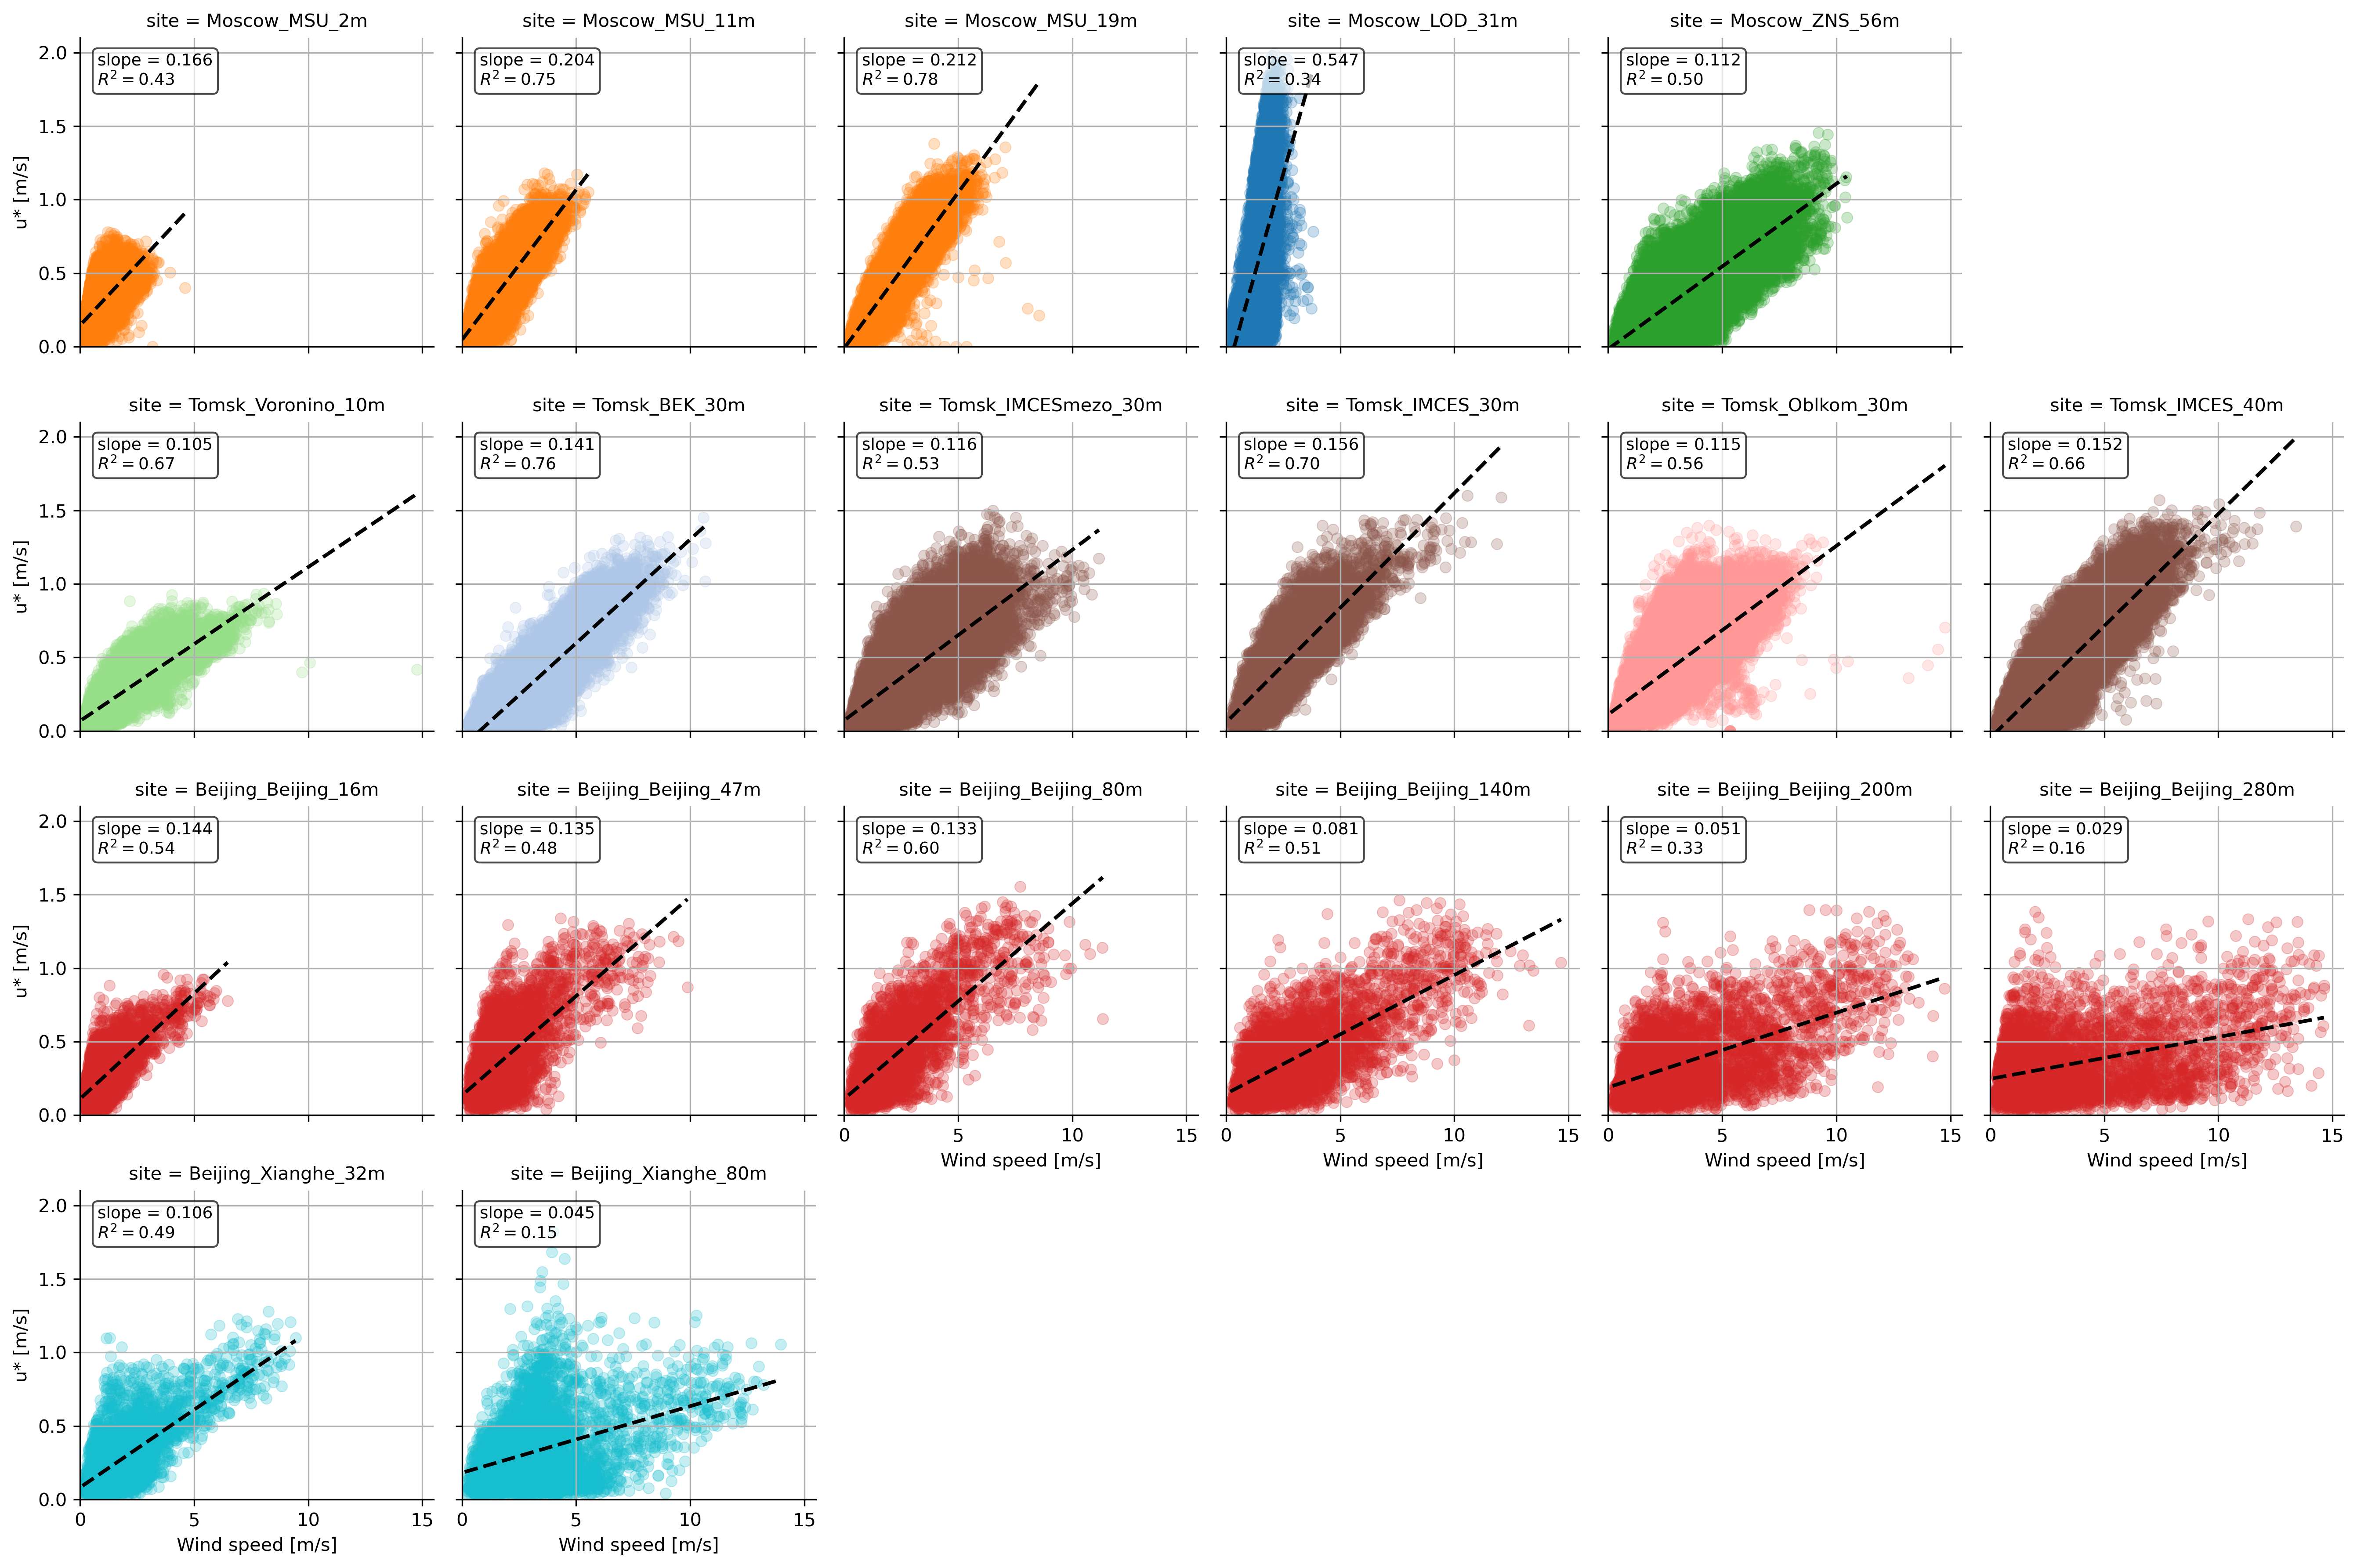

In [63]:
from matplotlib import pyplot as plt
import seaborn as sns

def scatter_with_trend(x_vals, y_vals, **kwargs):
    """
    Рисует scatterplot и линейный тренд на текущей оси.
    
    Параметры:
    data   - подмножество DataFrame (принимается для совместимости с FacetGrid.map)
    x_vals - массив значений для оси X
    y_vals - массив значений для оси Y
    **kwargs - дополнительные параметры (например, alpha) для sns.scatterplot
    """
    # Удаляем пропуски
    mask = ~(np.isnan(x_vals) | np.isnan(y_vals))
    x_clean = x_vals[mask]
    y_clean = y_vals[mask]
    
    # Строим scatterplot
    sns.scatterplot(x=x_clean, y=y_clean, **kwargs)
    
    # Добавляем линейный тренд, если точек достаточно
    if len(x_clean) > 1:
        coef = np.polyfit(x_clean, y_clean, 1)
        slope, intercept = coef[0], coef[1]
        trend_line = np.poly1d(coef)
        x_range = np.linspace(x_clean.min(), x_clean.max(), 100)
        y_trend = trend_line(x_range)
        plt.plot(x_range, y_trend, '--k', linewidth=2)

        # Расчёт R^2
        y_pred = trend_line(x_clean)
        ss_res = np.sum((y_clean - y_pred) ** 2)
        ss_tot = np.sum((y_clean - np.mean(y_clean)) ** 2)
        r2 = 1 - (ss_res / ss_tot)
        
        # Добавляем текст на график (правый верхний угол)
        ax = plt.gca()
        text_str = f'slope = {slope:.3f}\n$R^2 = {r2:.2f}$'
        ax.text(0.05, 0.95, text_str,
                transform=ax.transAxes,
                verticalalignment='top',
                horizontalalignment='left',
                fontsize=9,
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

g = sns.FacetGrid(df_merged, col="site", col_wrap=6)
g.map(scatter_with_trend, "Wind_vel", "Ustar", alpha=0.25)

unique_sites = np.unique(['_'.join(s.replace('mezo', '').split('_')[0:-1]) for s in df_merged['site'].unique()])

cmap = plt.get_cmap('tab20')
reds = np.array([c[0] / (c[1] + c[2]) for c in cmap.colors]) 
cmap_idx = np.argsort(reds)
cmap = np.array(cmap.colors)[cmap_idx]


i_color_urb = len(cmap)-1
i_color_rur = 0

color4sites = {}

for site in unique_sites:
    if 'Oblkom' in site or 'MSU' in site or 'IMCES' in site or 'Beijing_Beijing' in site:
        color4sites[site] = cmap[i_color_urb]
        i_color_urb -= 1
    else:
        color4sites[site] = cmap[i_color_rur]
        i_color_rur += 1


for ax in g.axes.flat:
    title = ax.get_title()
    if 'dummy' in title:
        ax.set_visible(False)
        continue
    
    unique_site = '_'.join(title.replace('site = ', '').replace('mezo', '').split('_')[0:-1])
    
    
    ax.grid(True)
    ylim = ax.get_ylim()
    xlim = ax.get_xlim()
    
    ax.set_xlim(0, xlim[1])
    ax.set_ylim(0, ylim[1])

    for collection in ax.collections:
        if isinstance(collection, plt.matplotlib.collections.PathCollection):
            collection.set_color(color4sites[unique_site])
    
g.set_xlabels('Wind speed [m/s]')
g.set_ylabels('u* [m/s]')


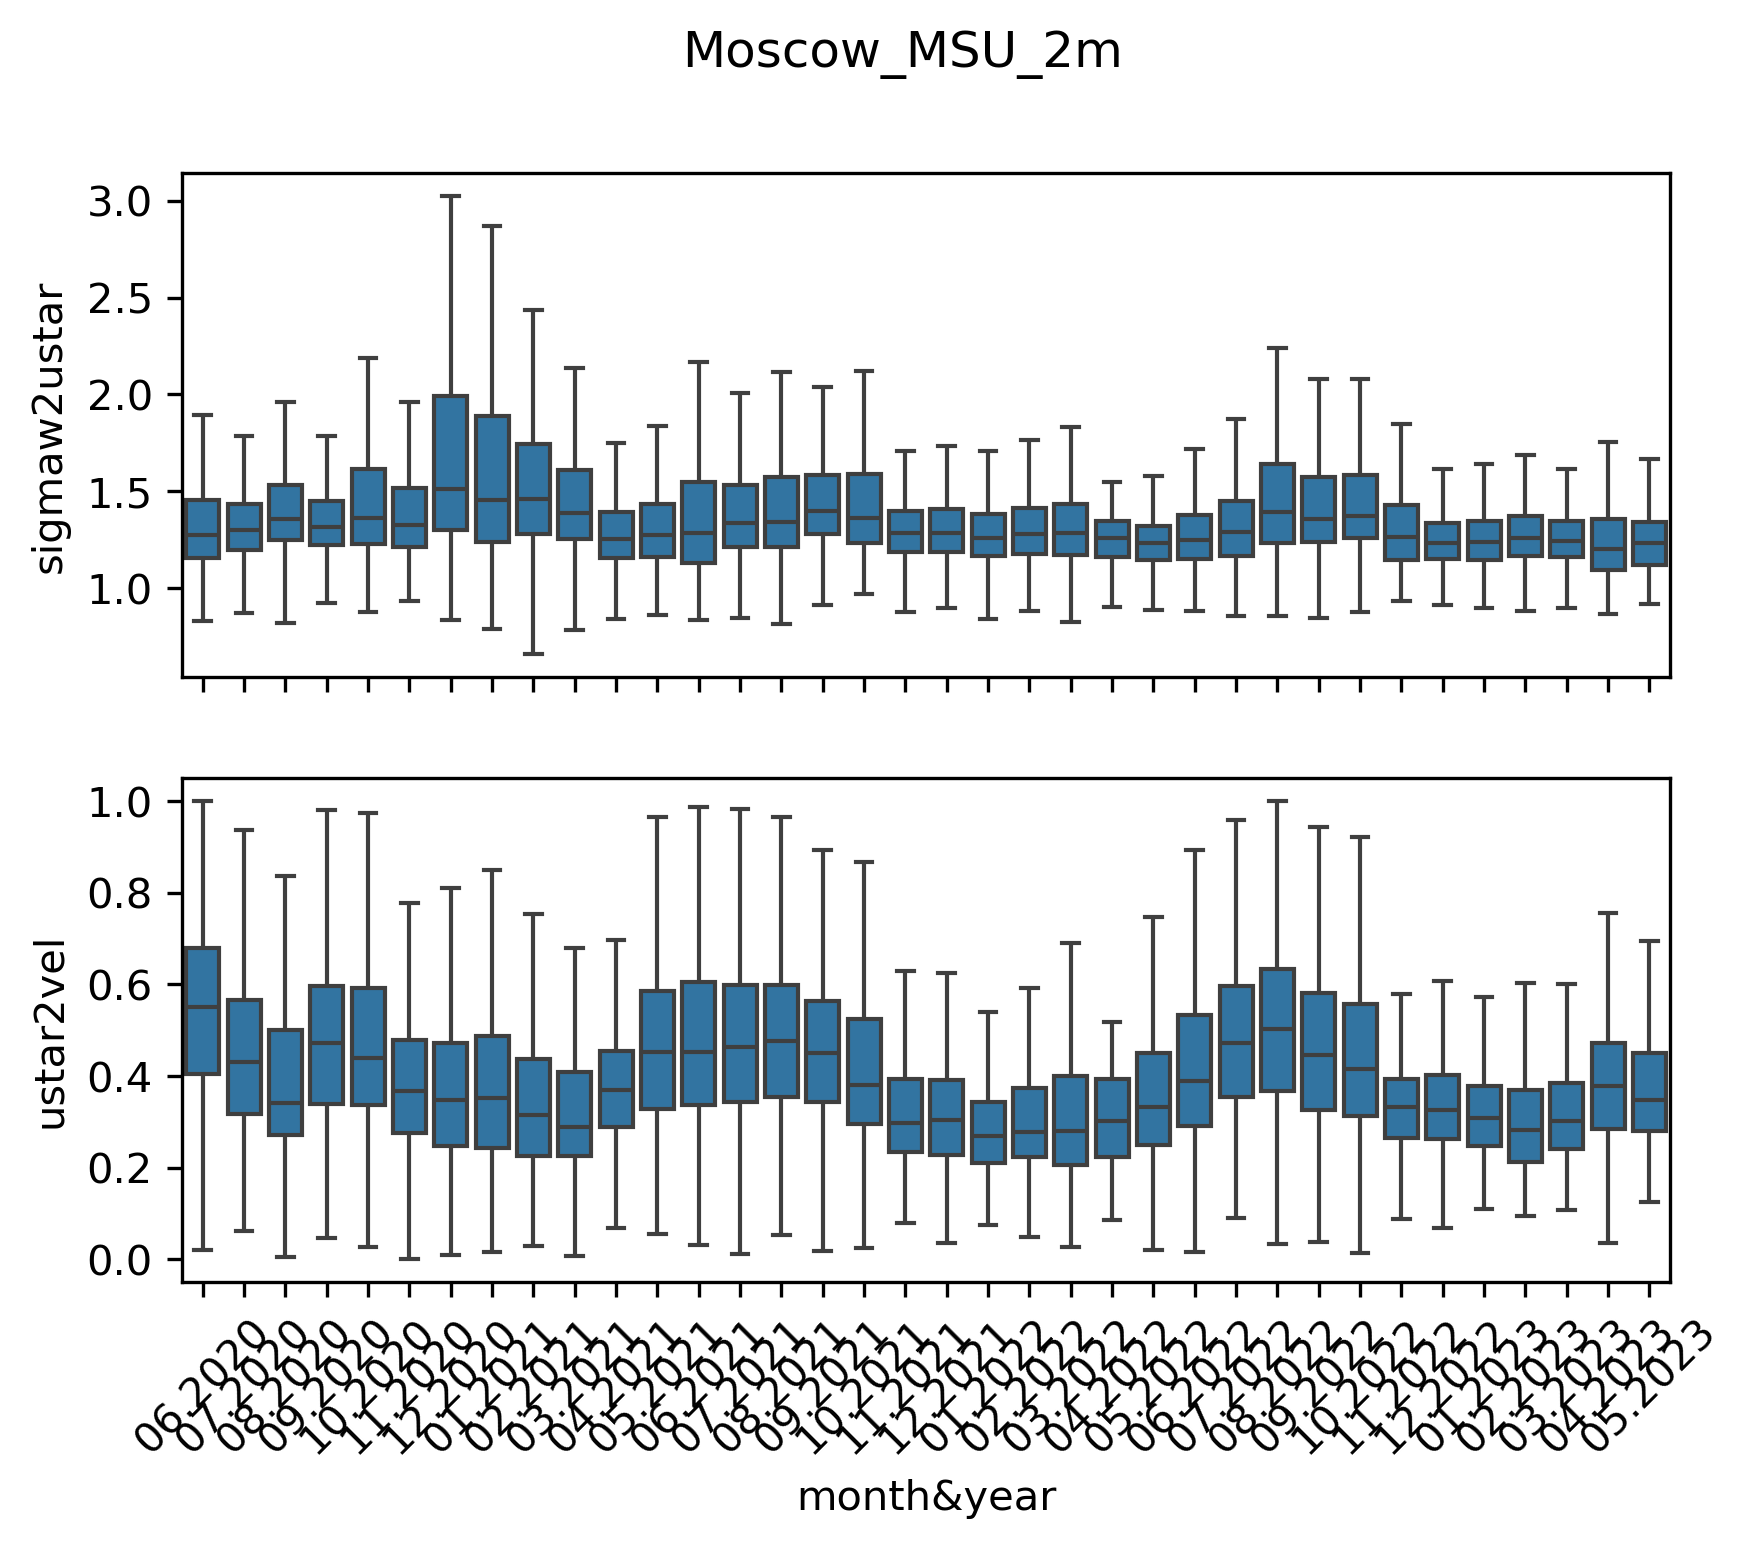

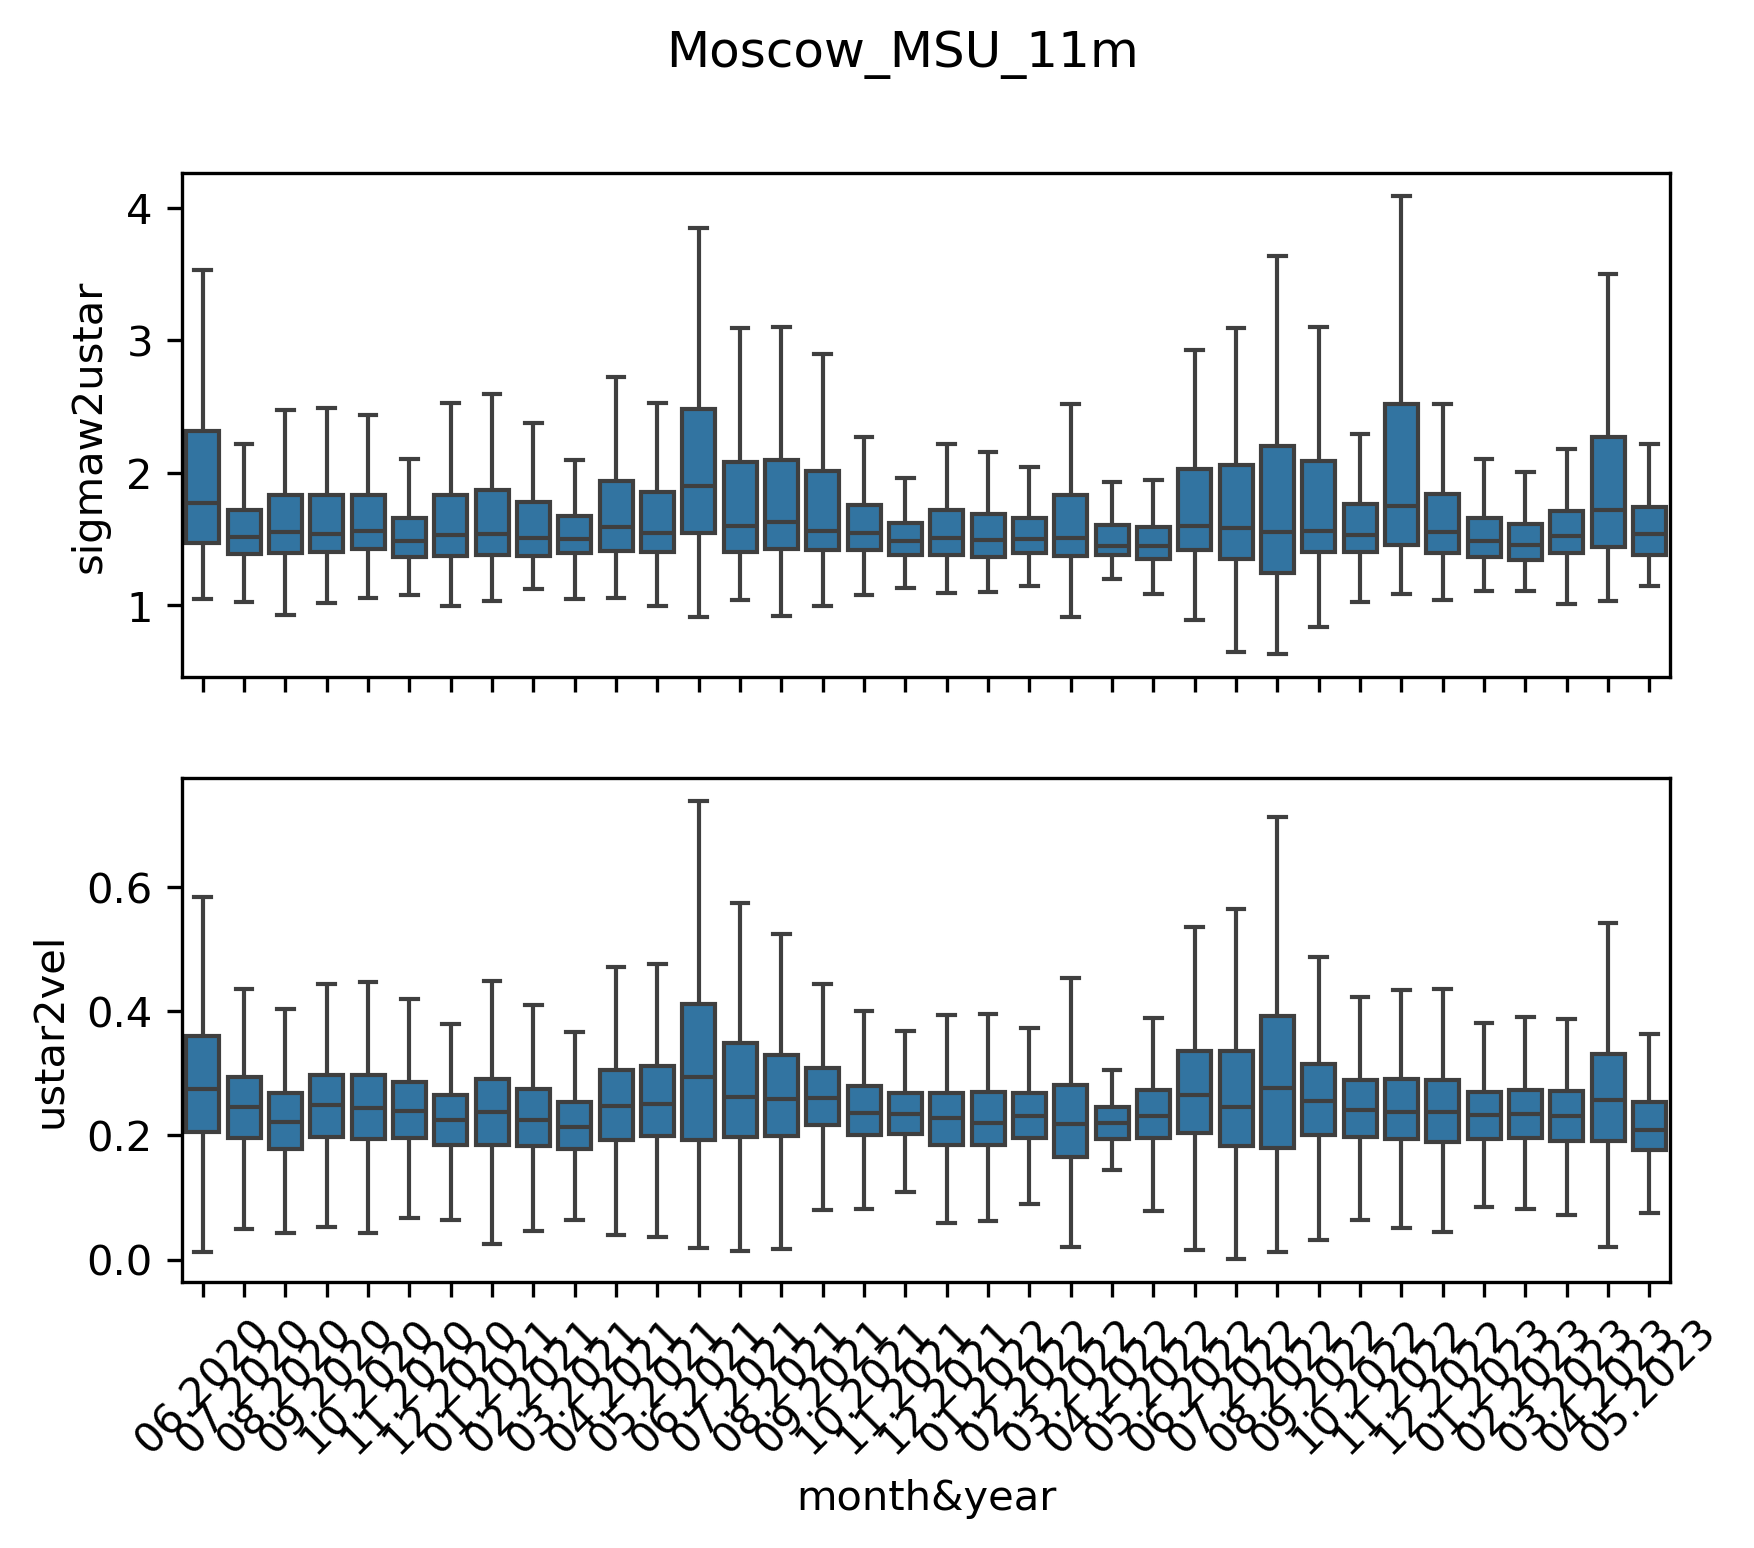

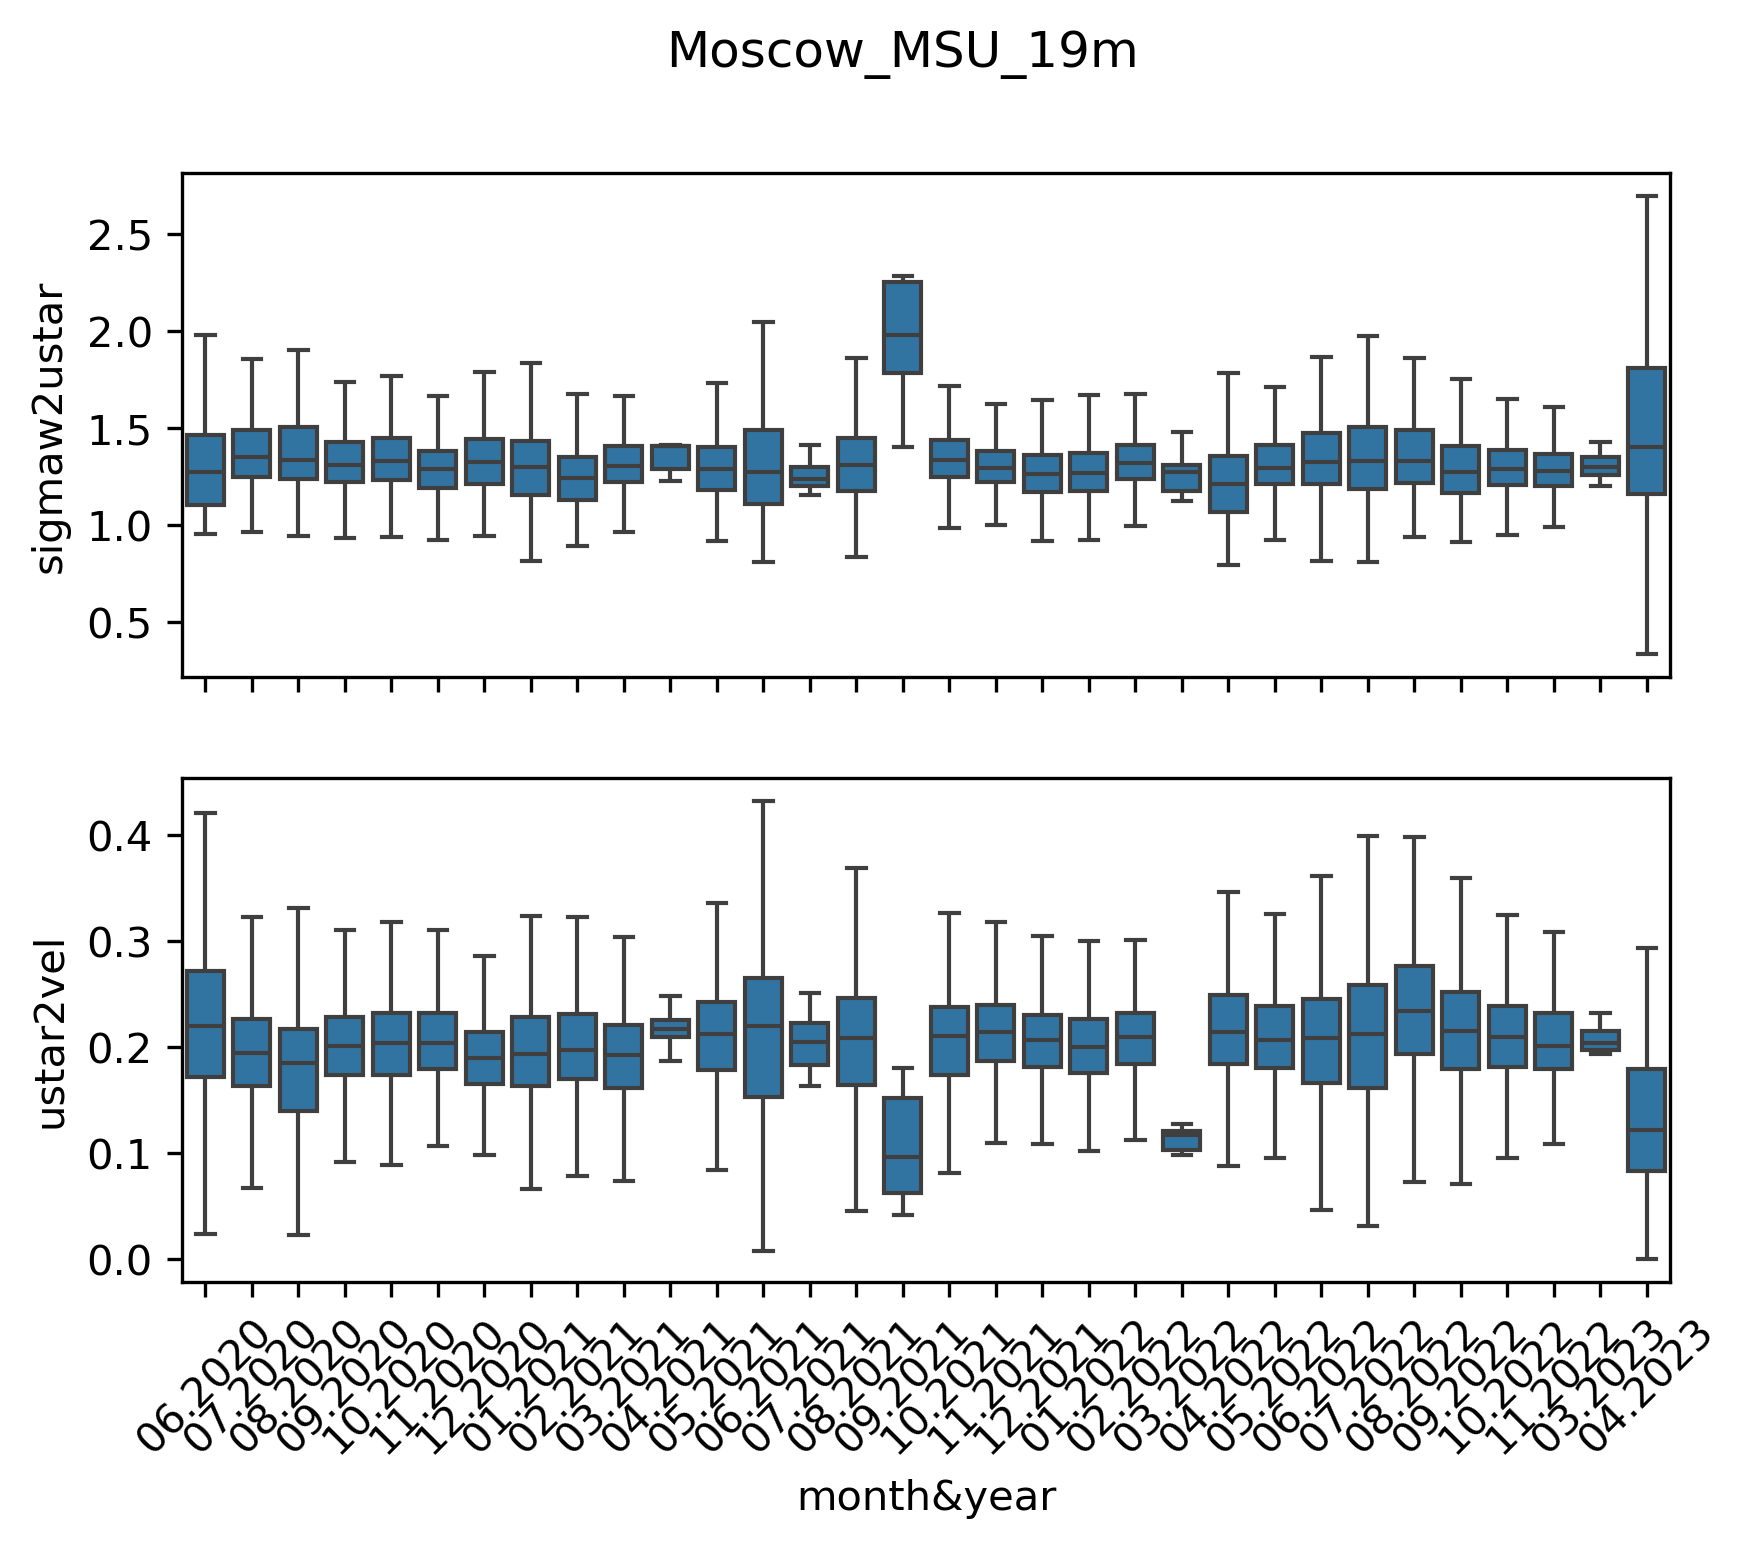

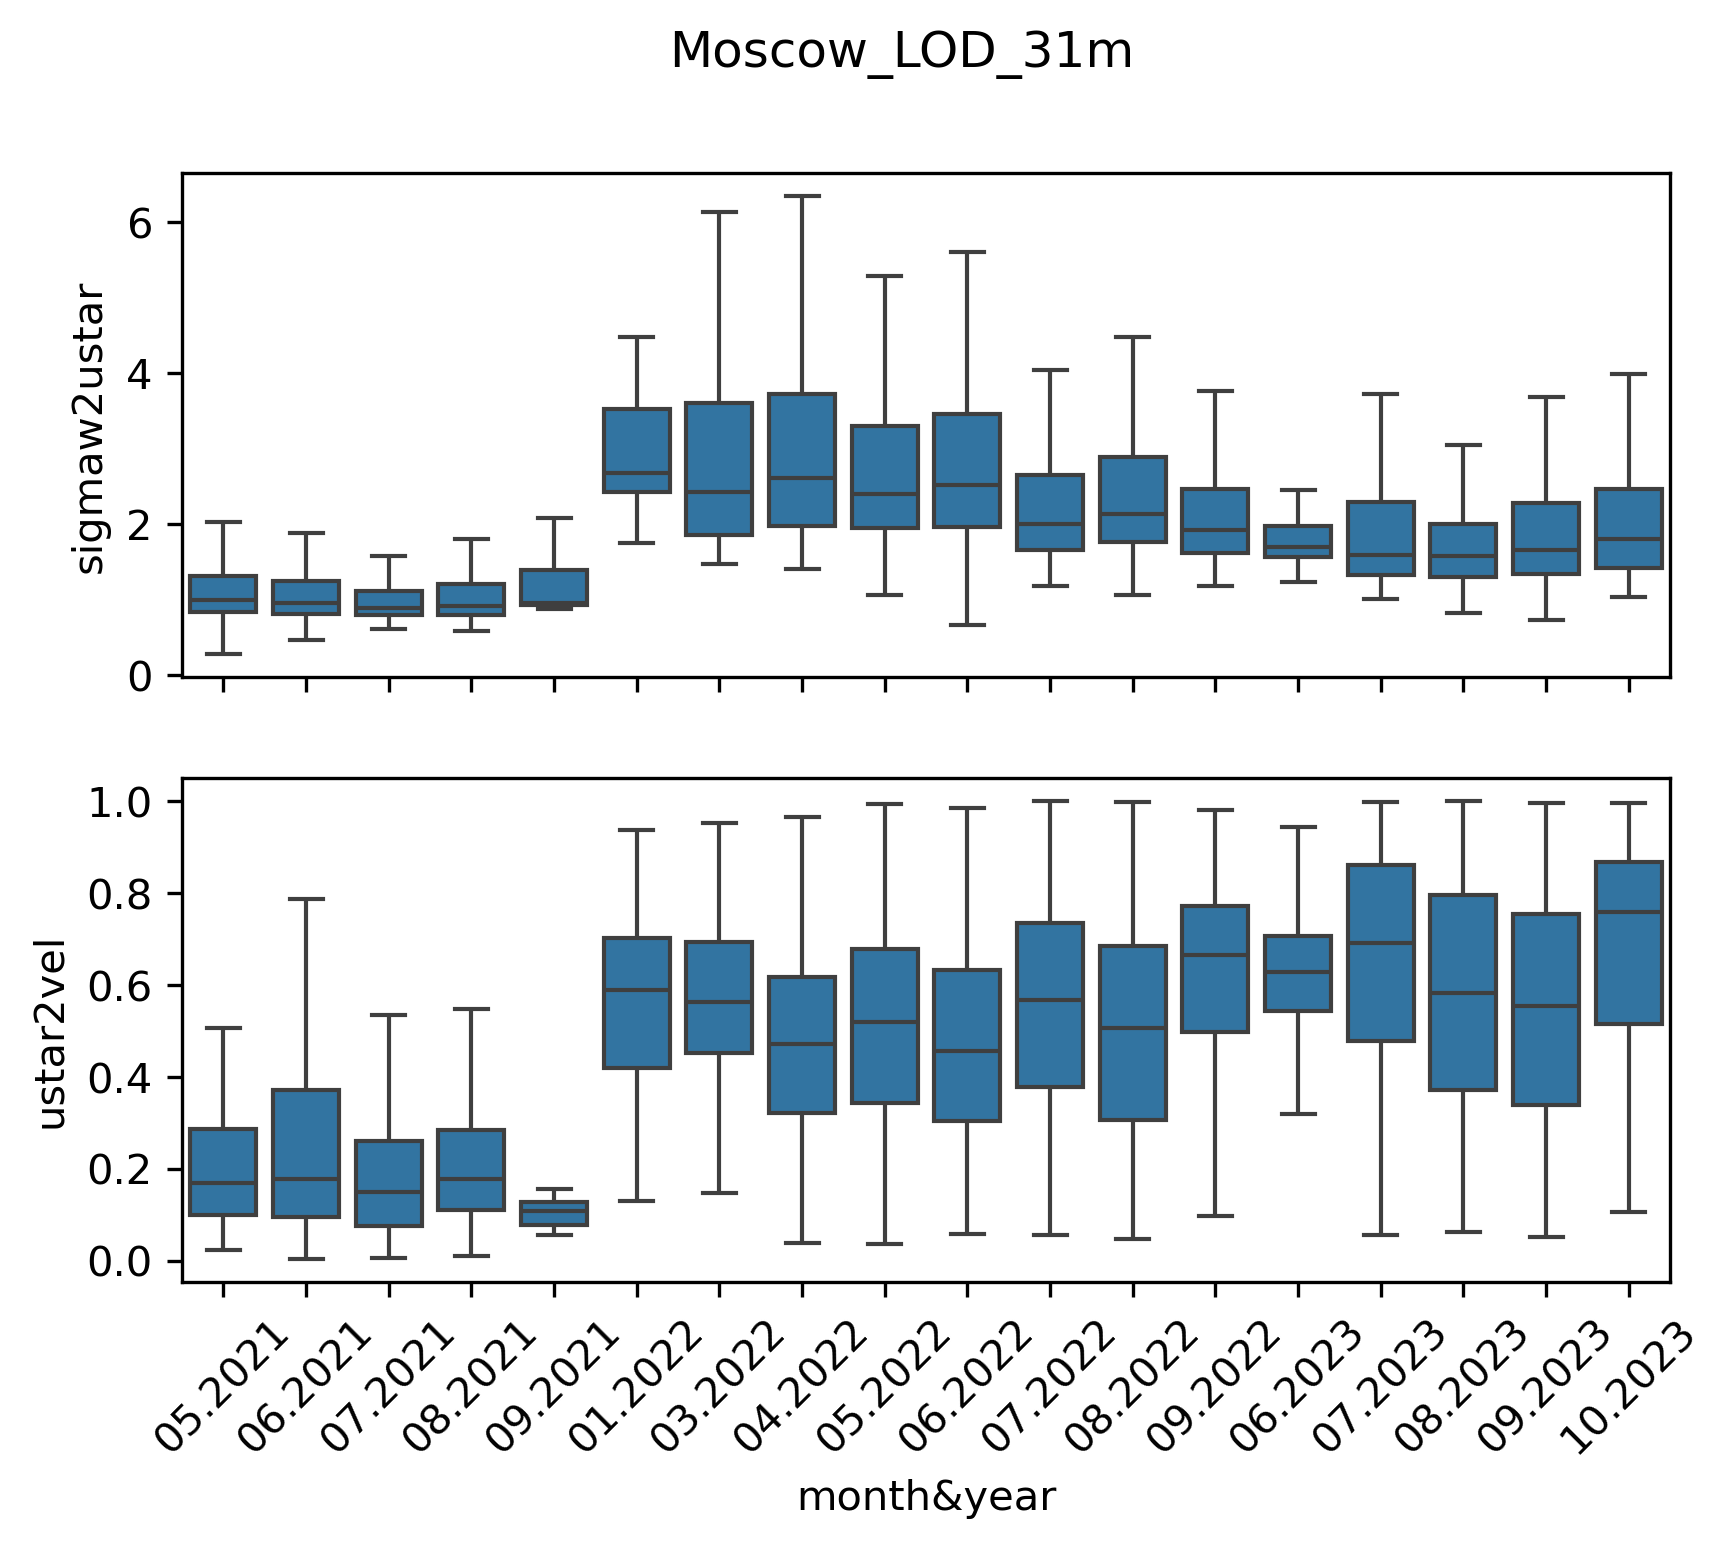

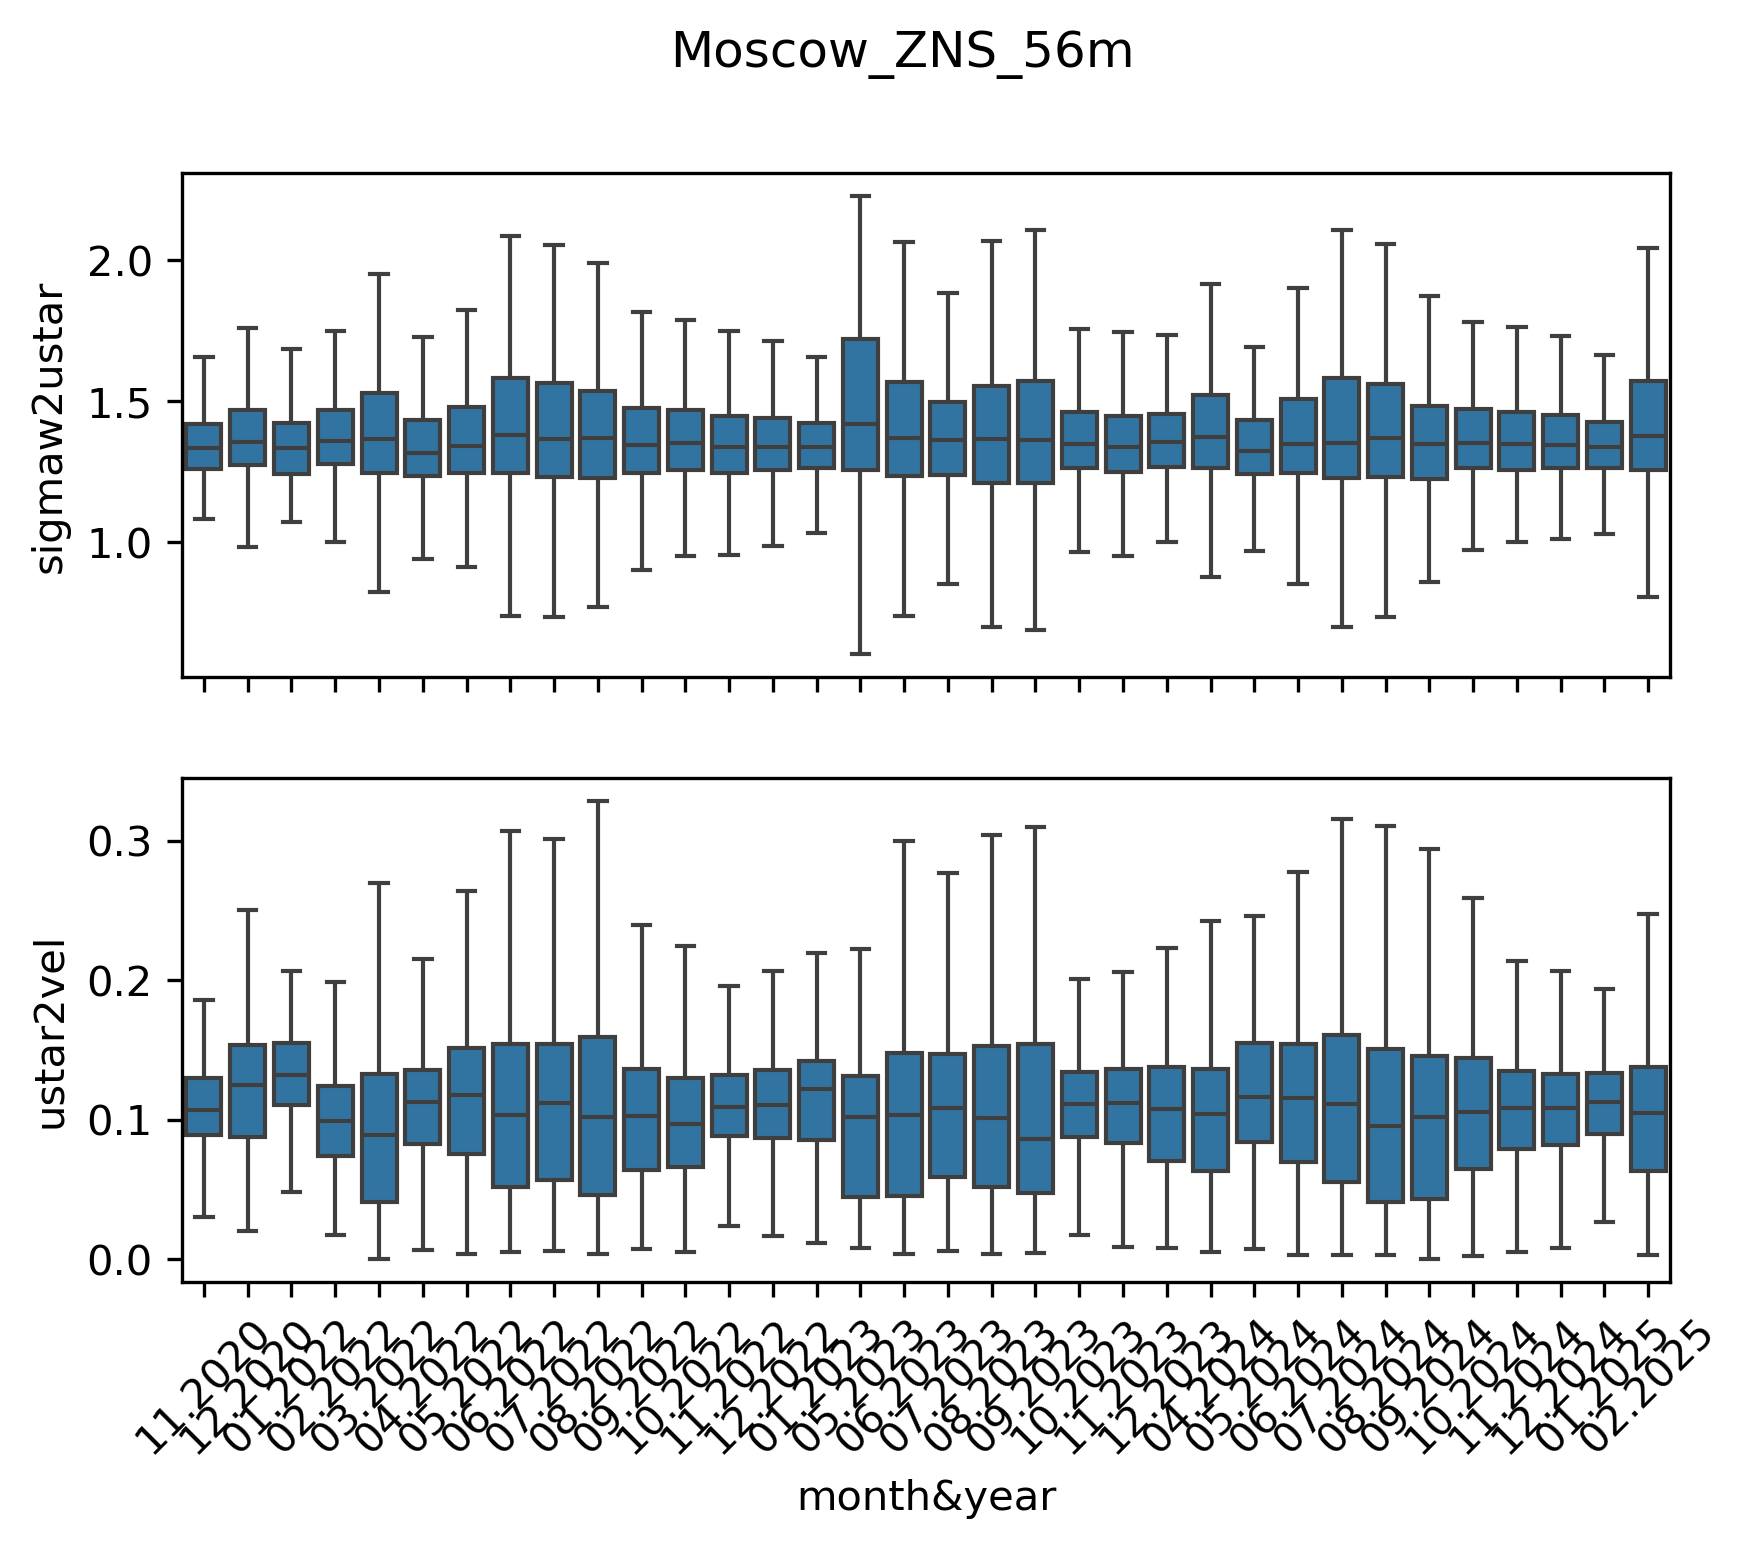

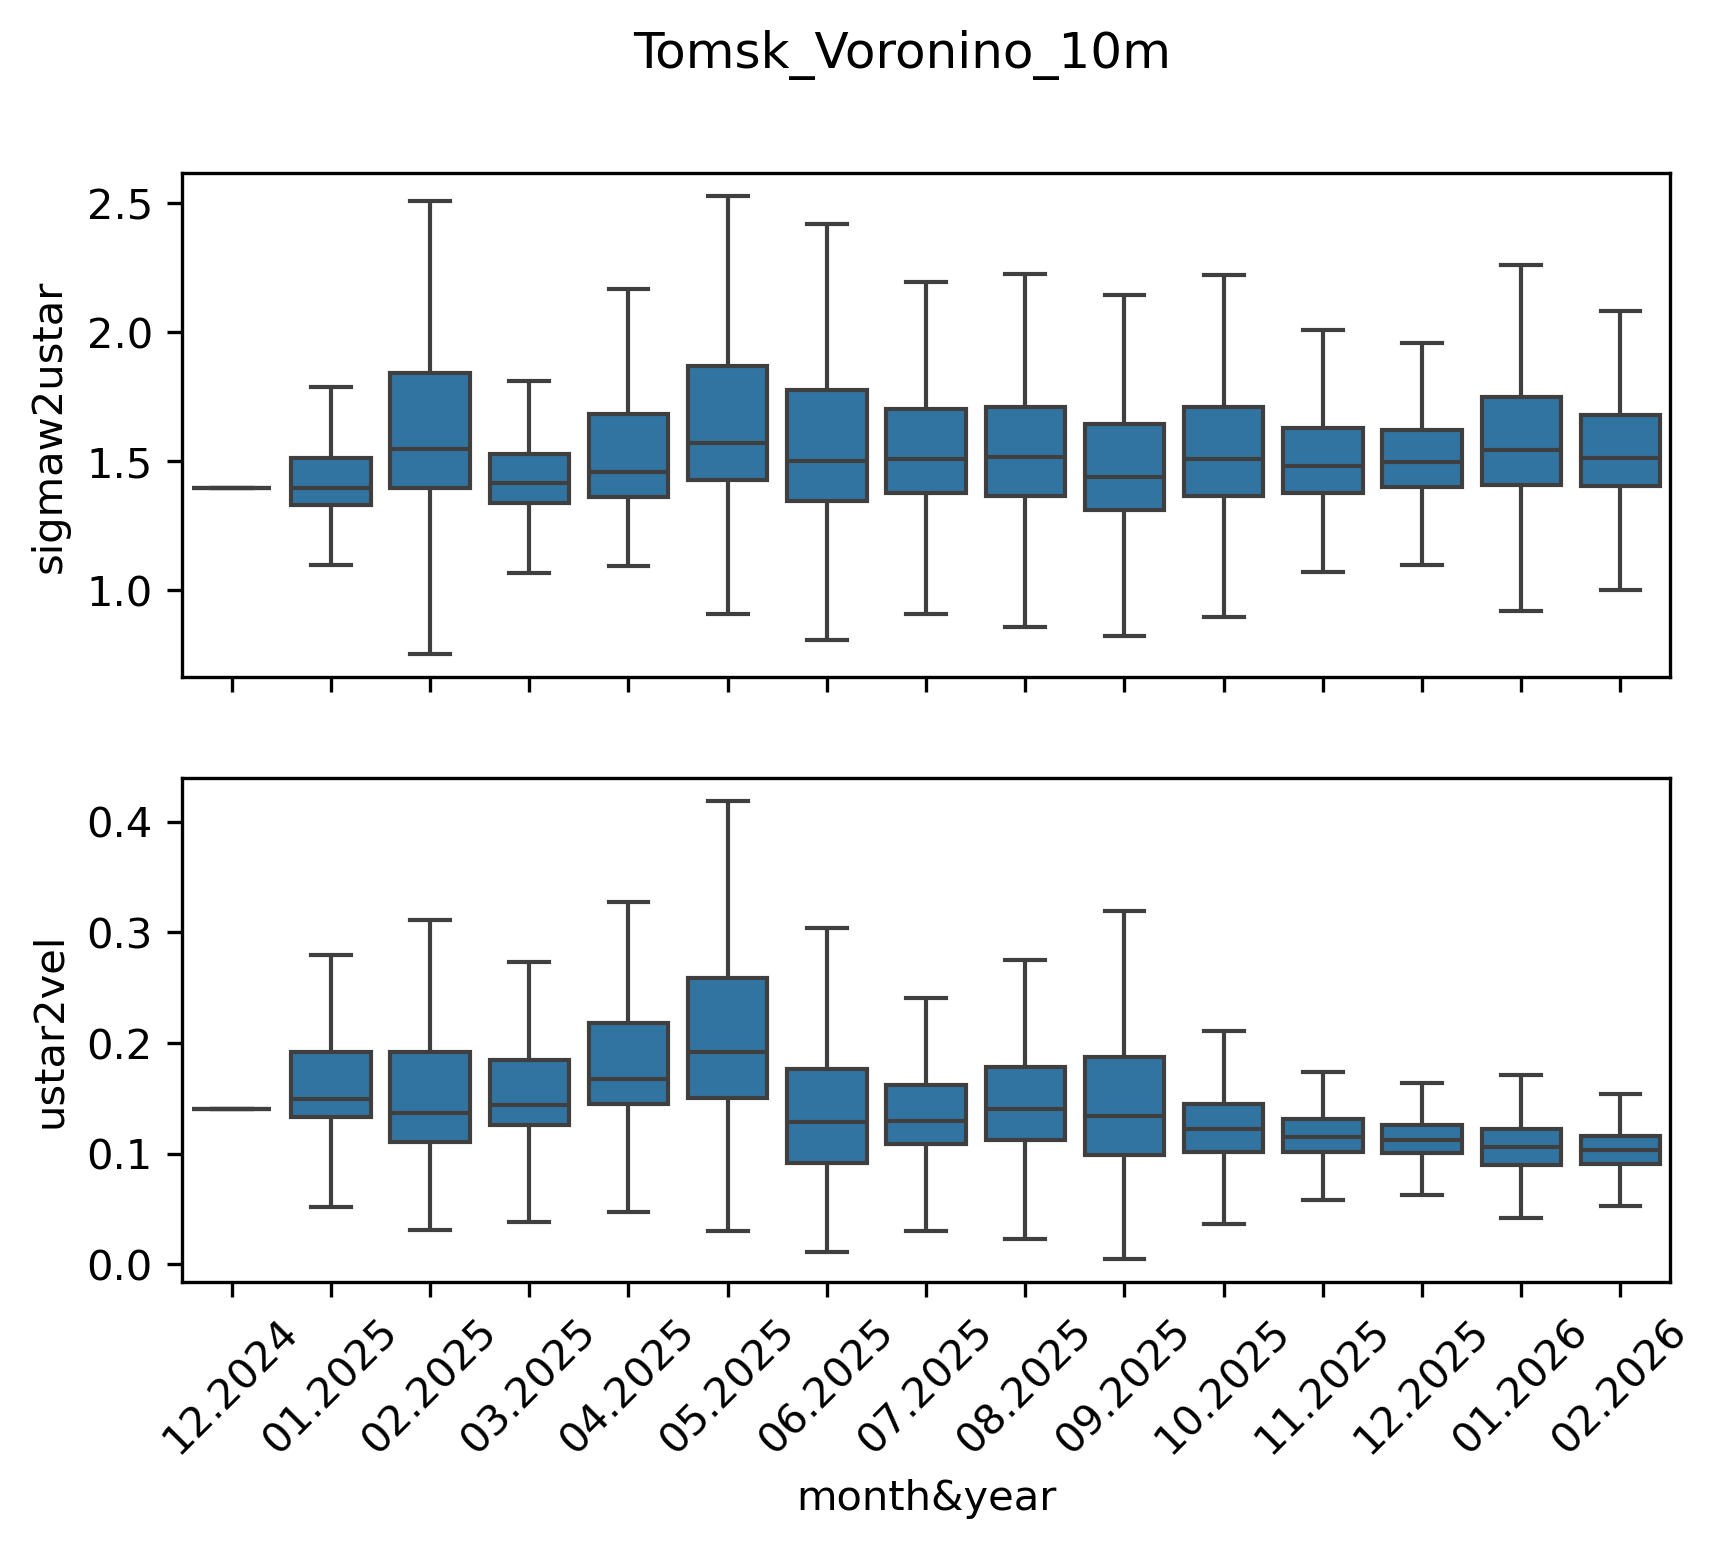

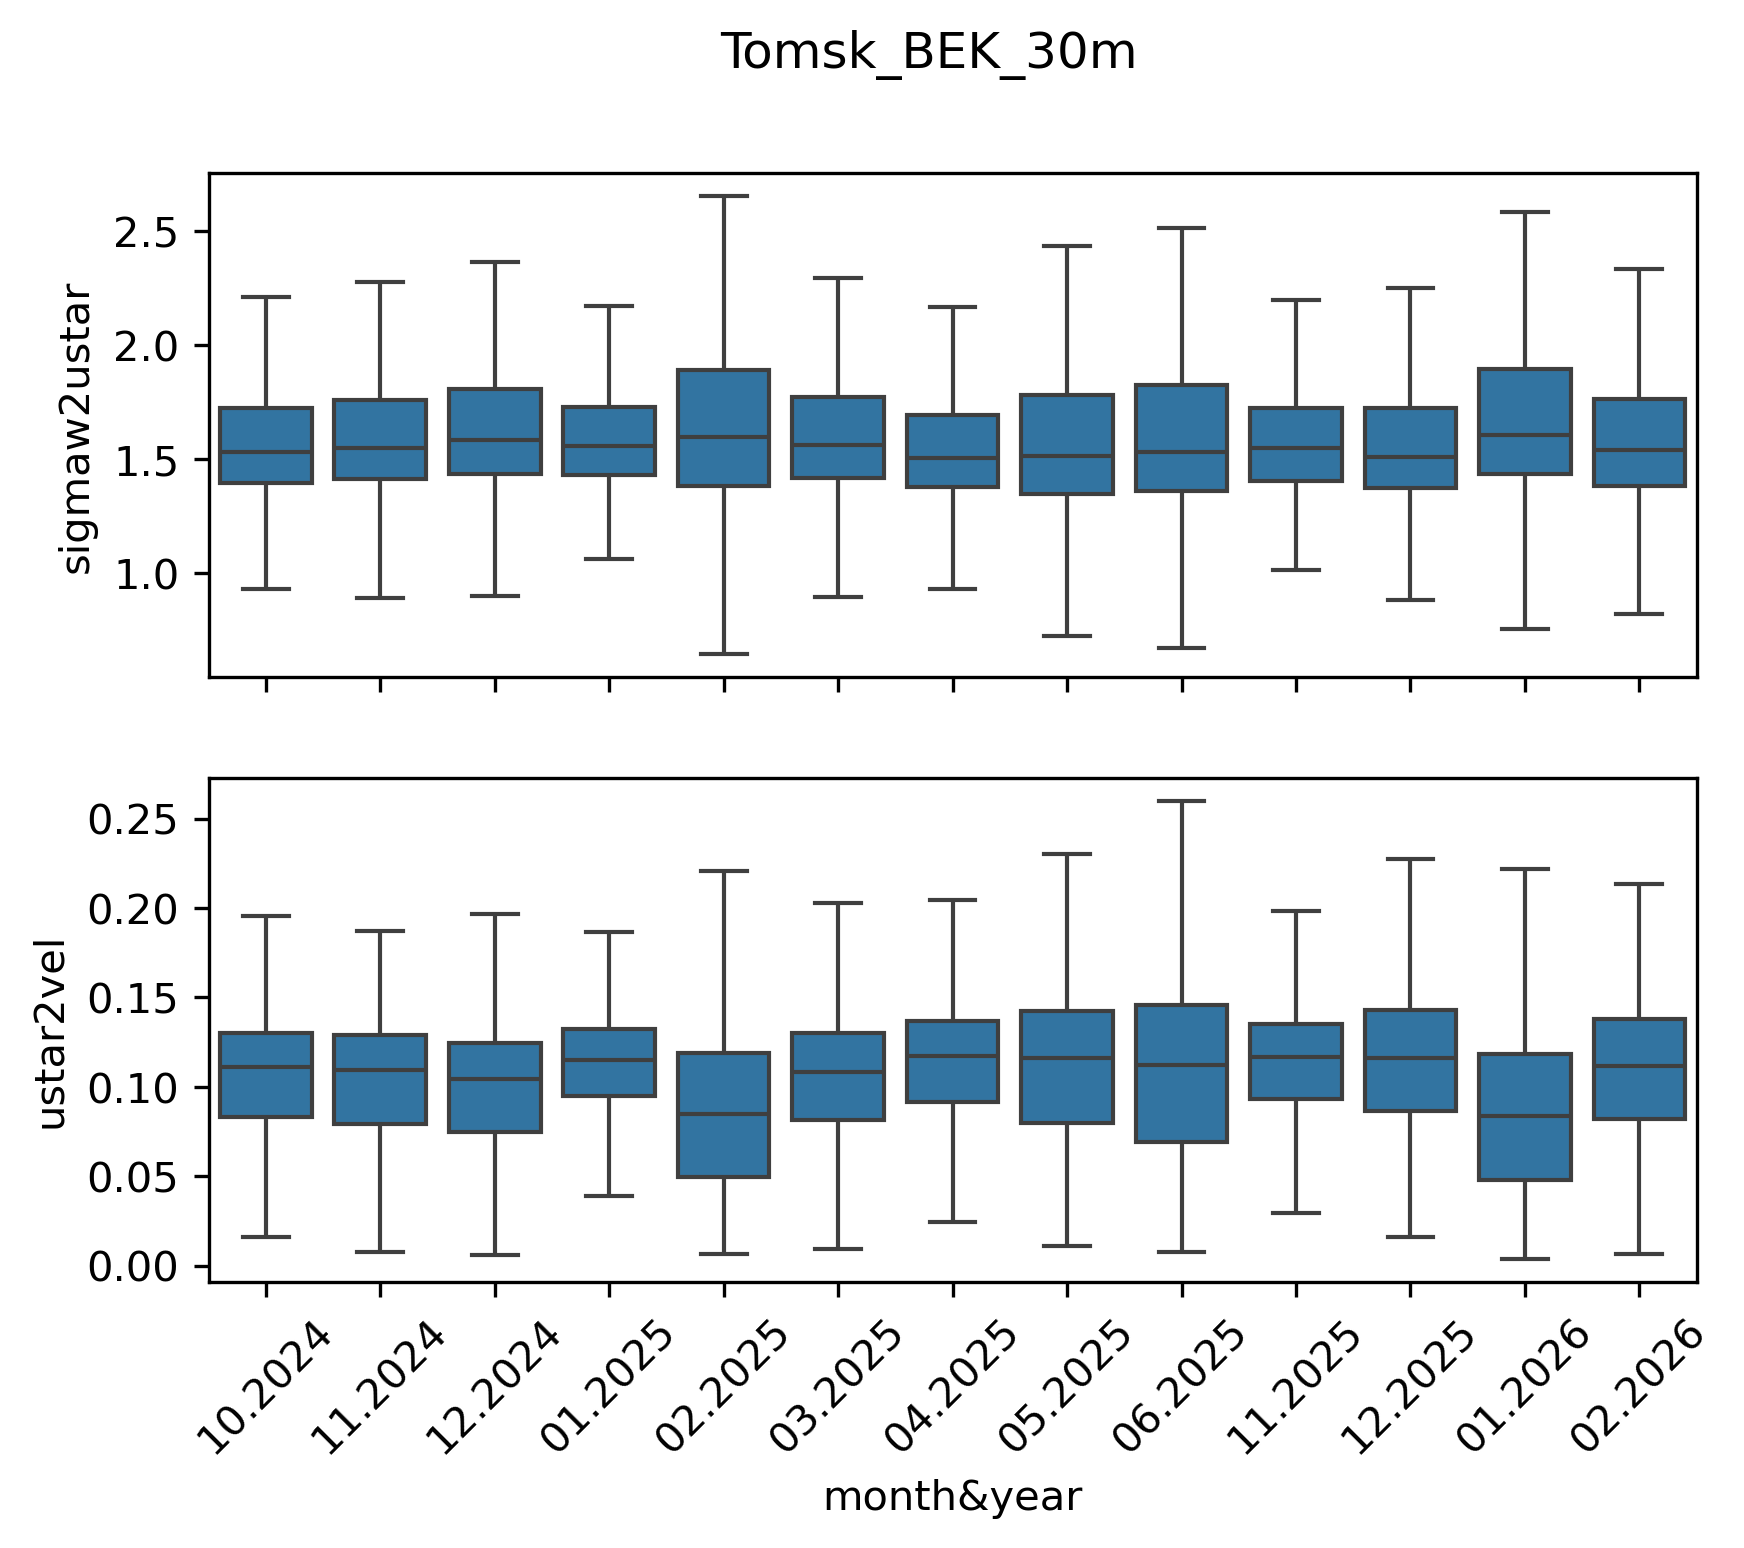

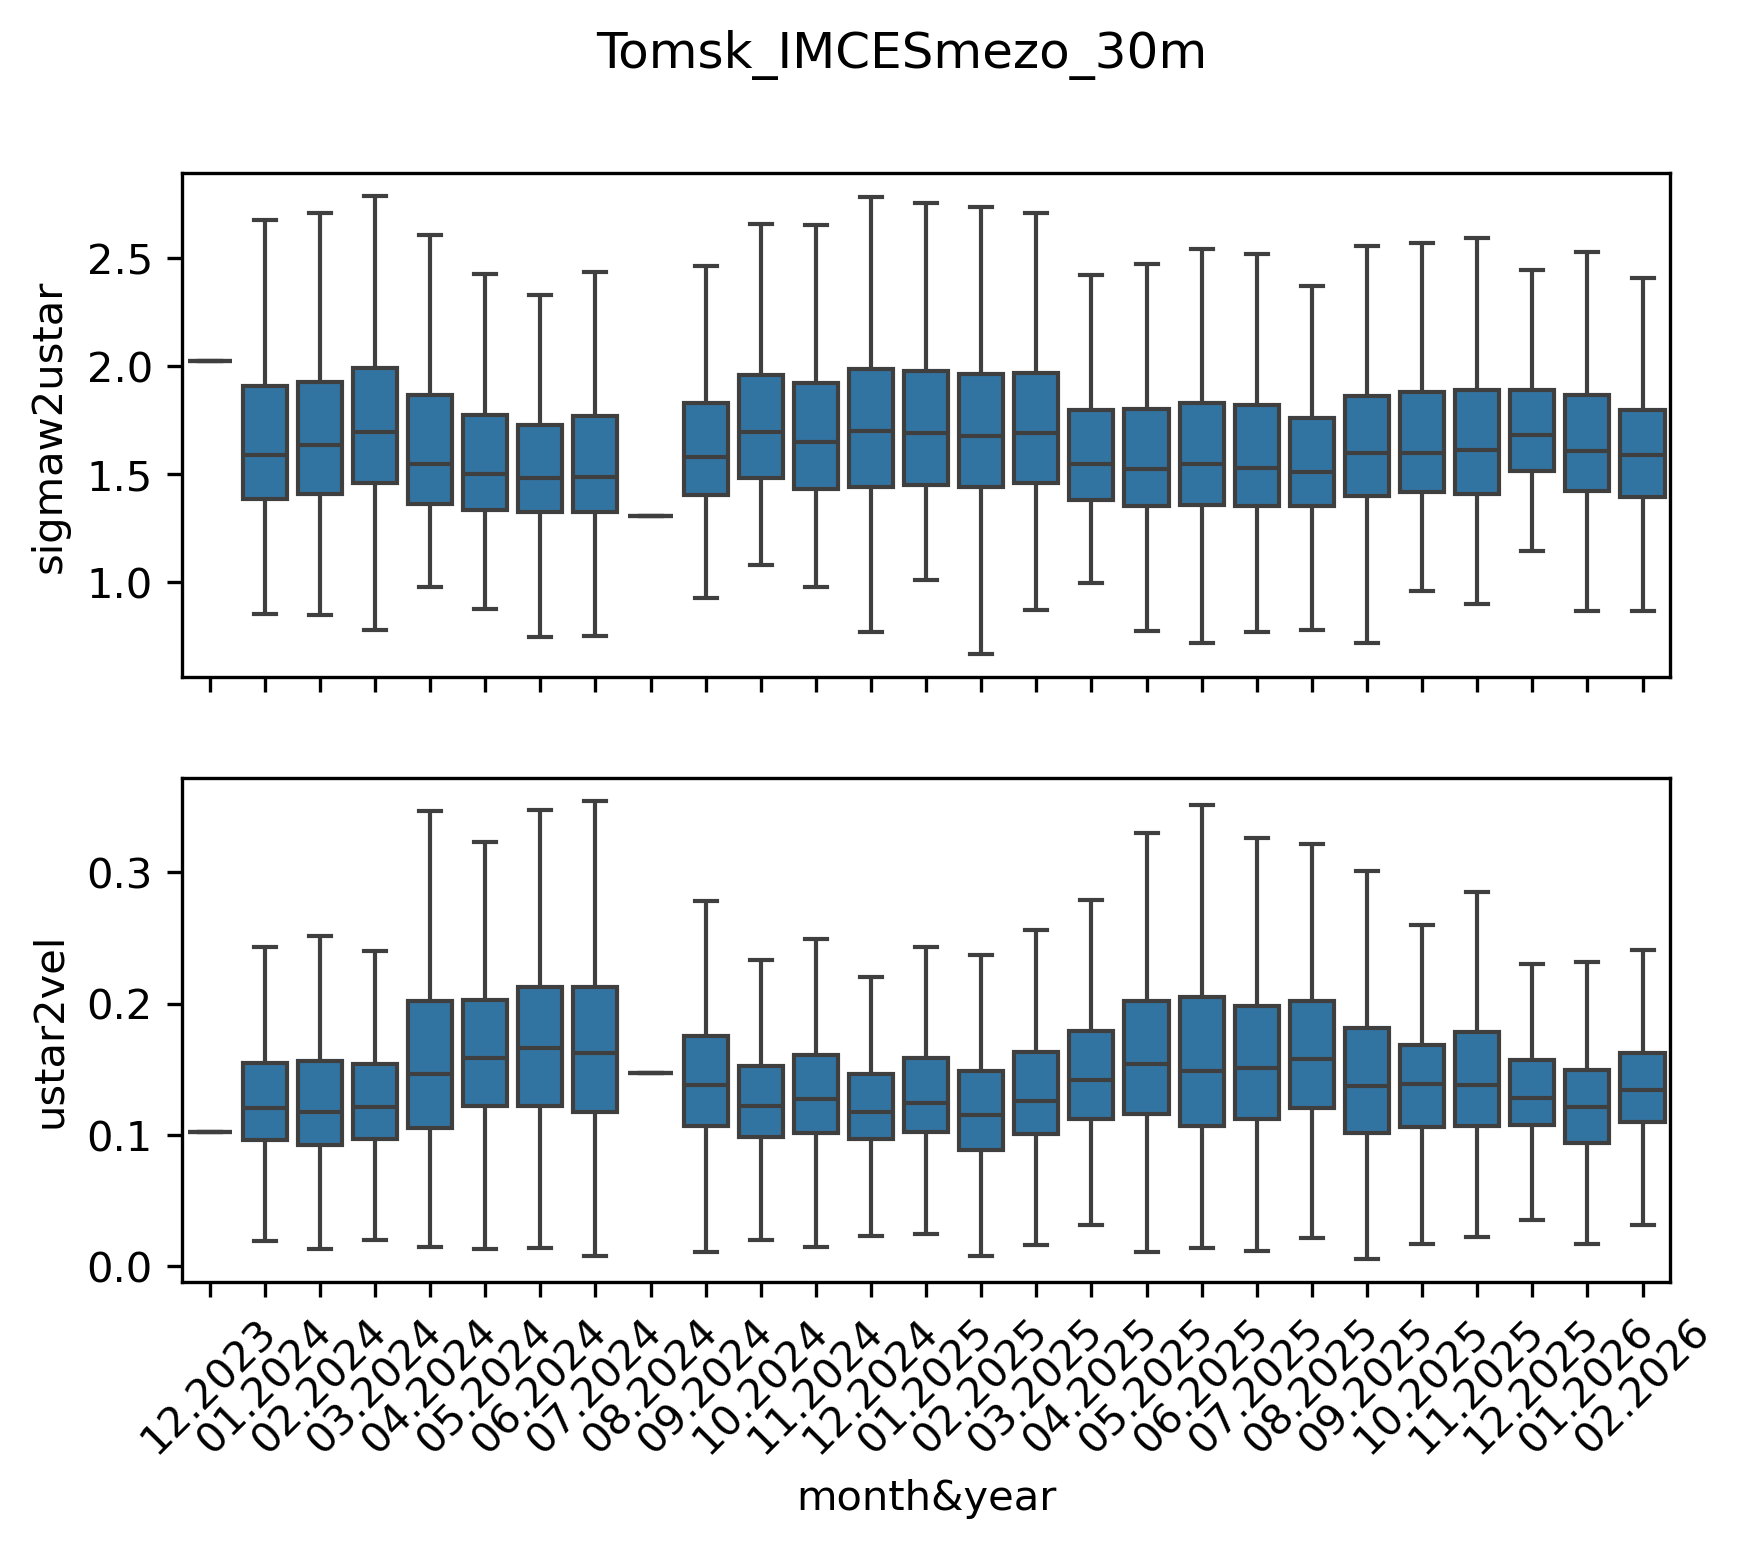

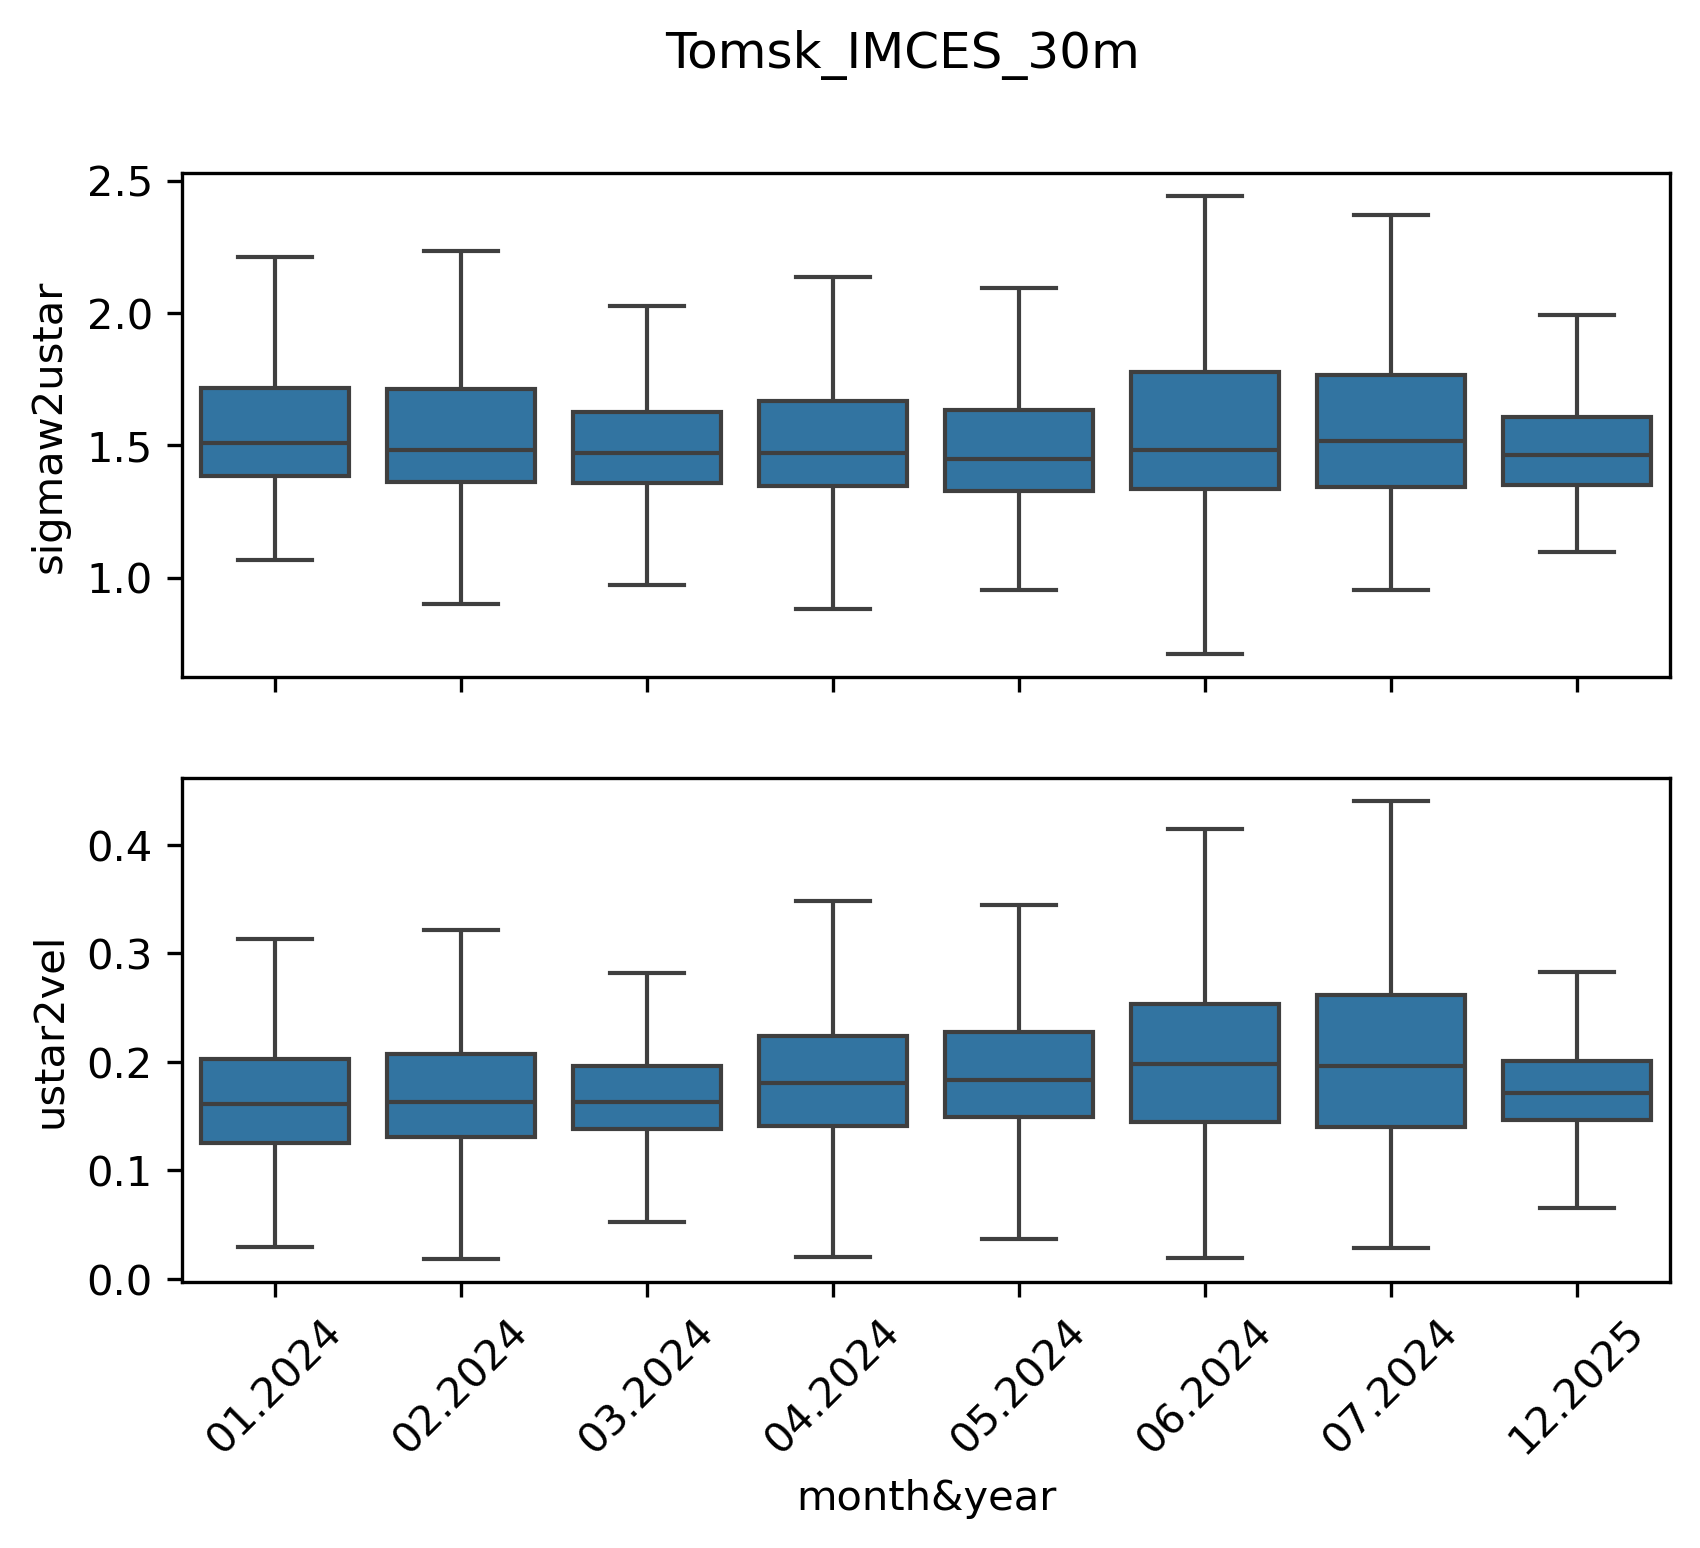

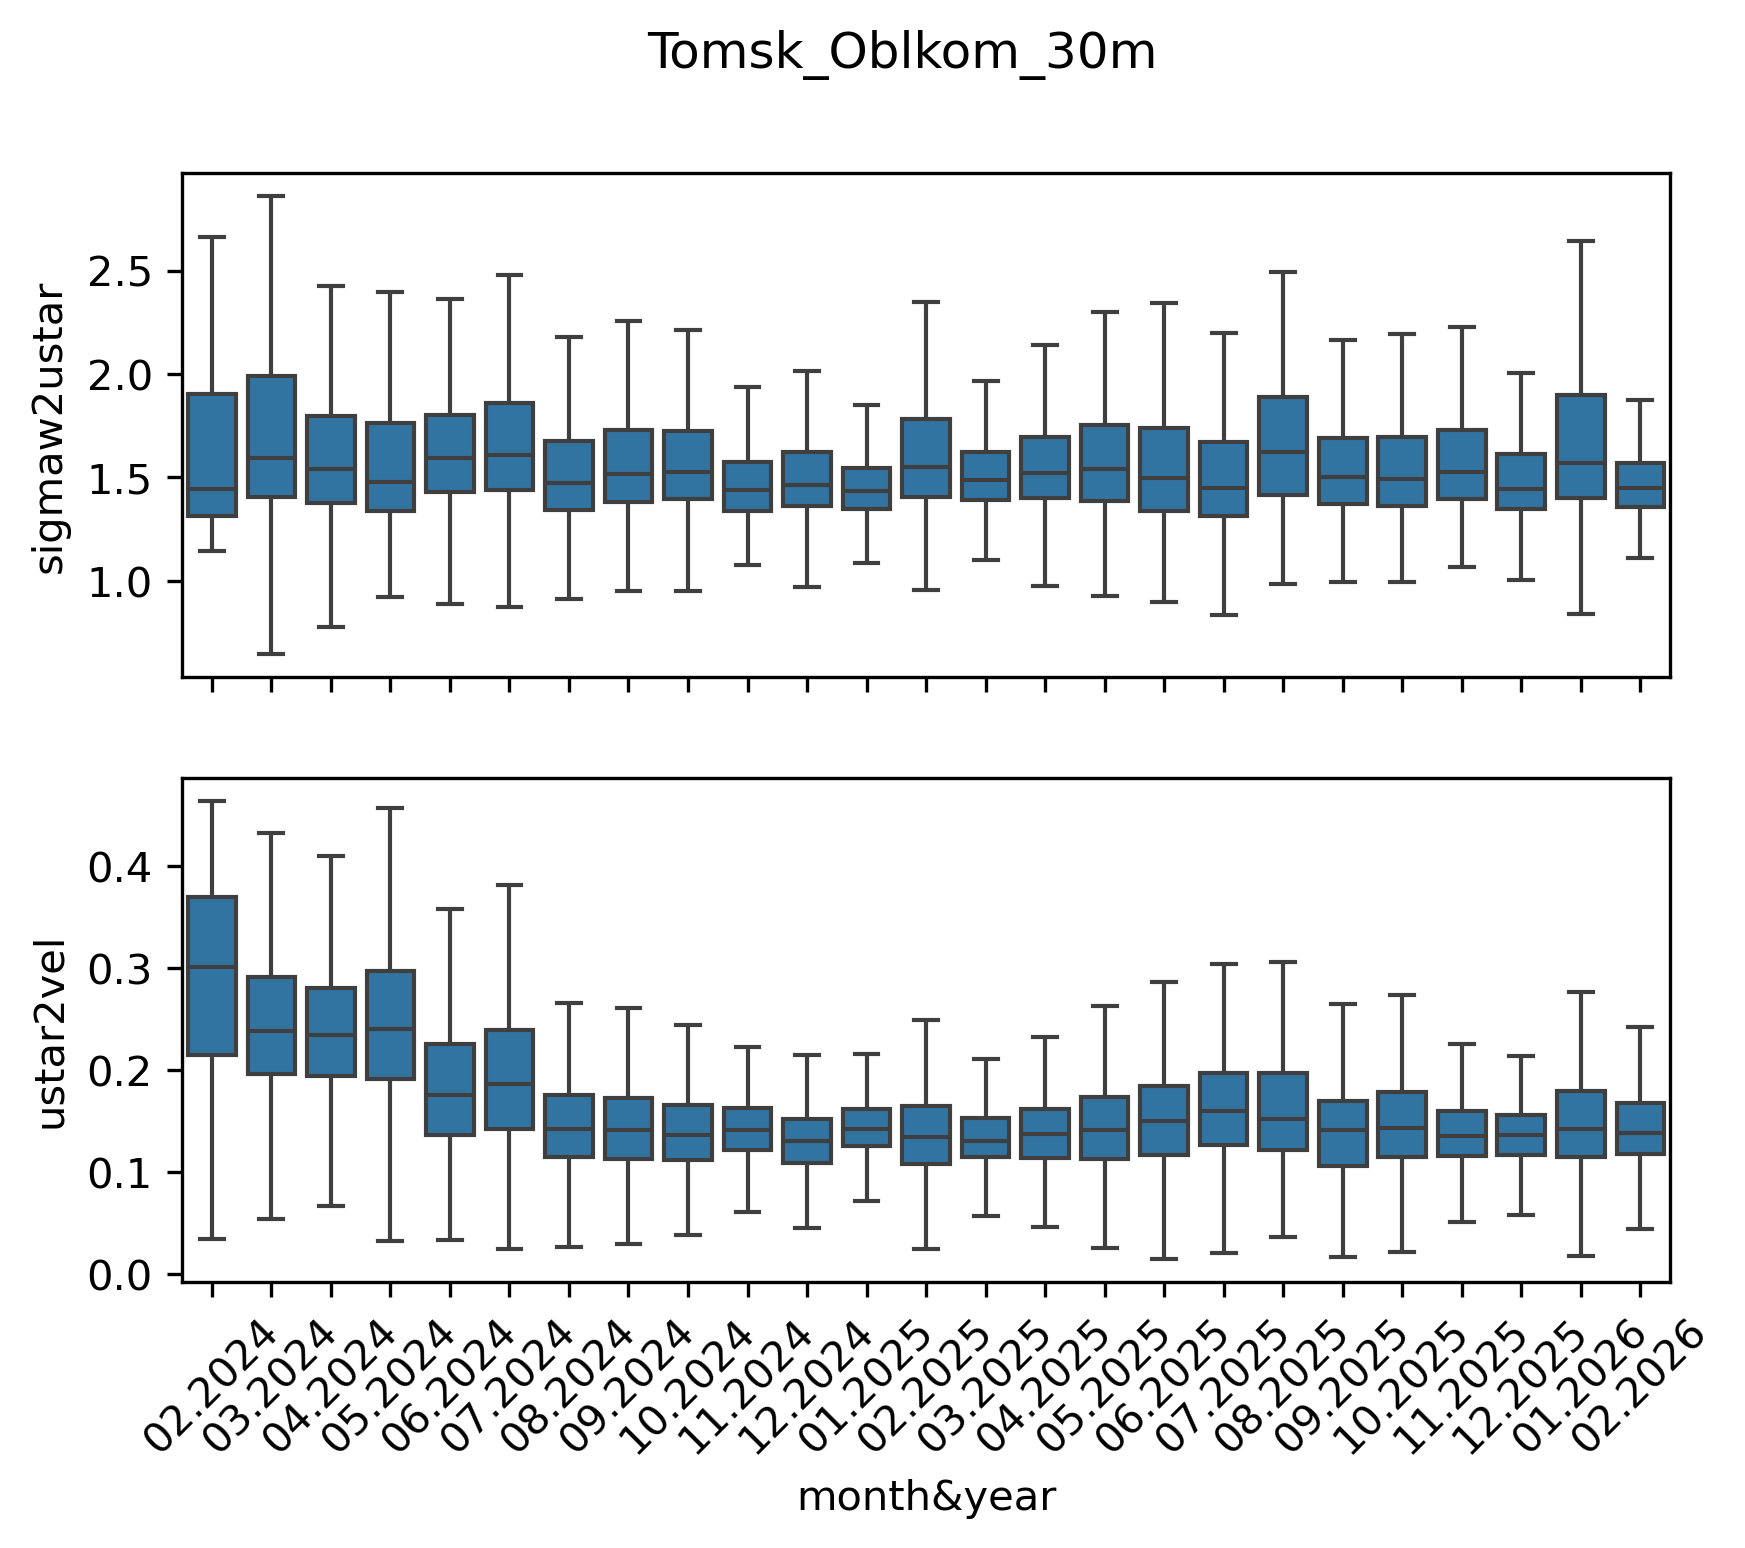

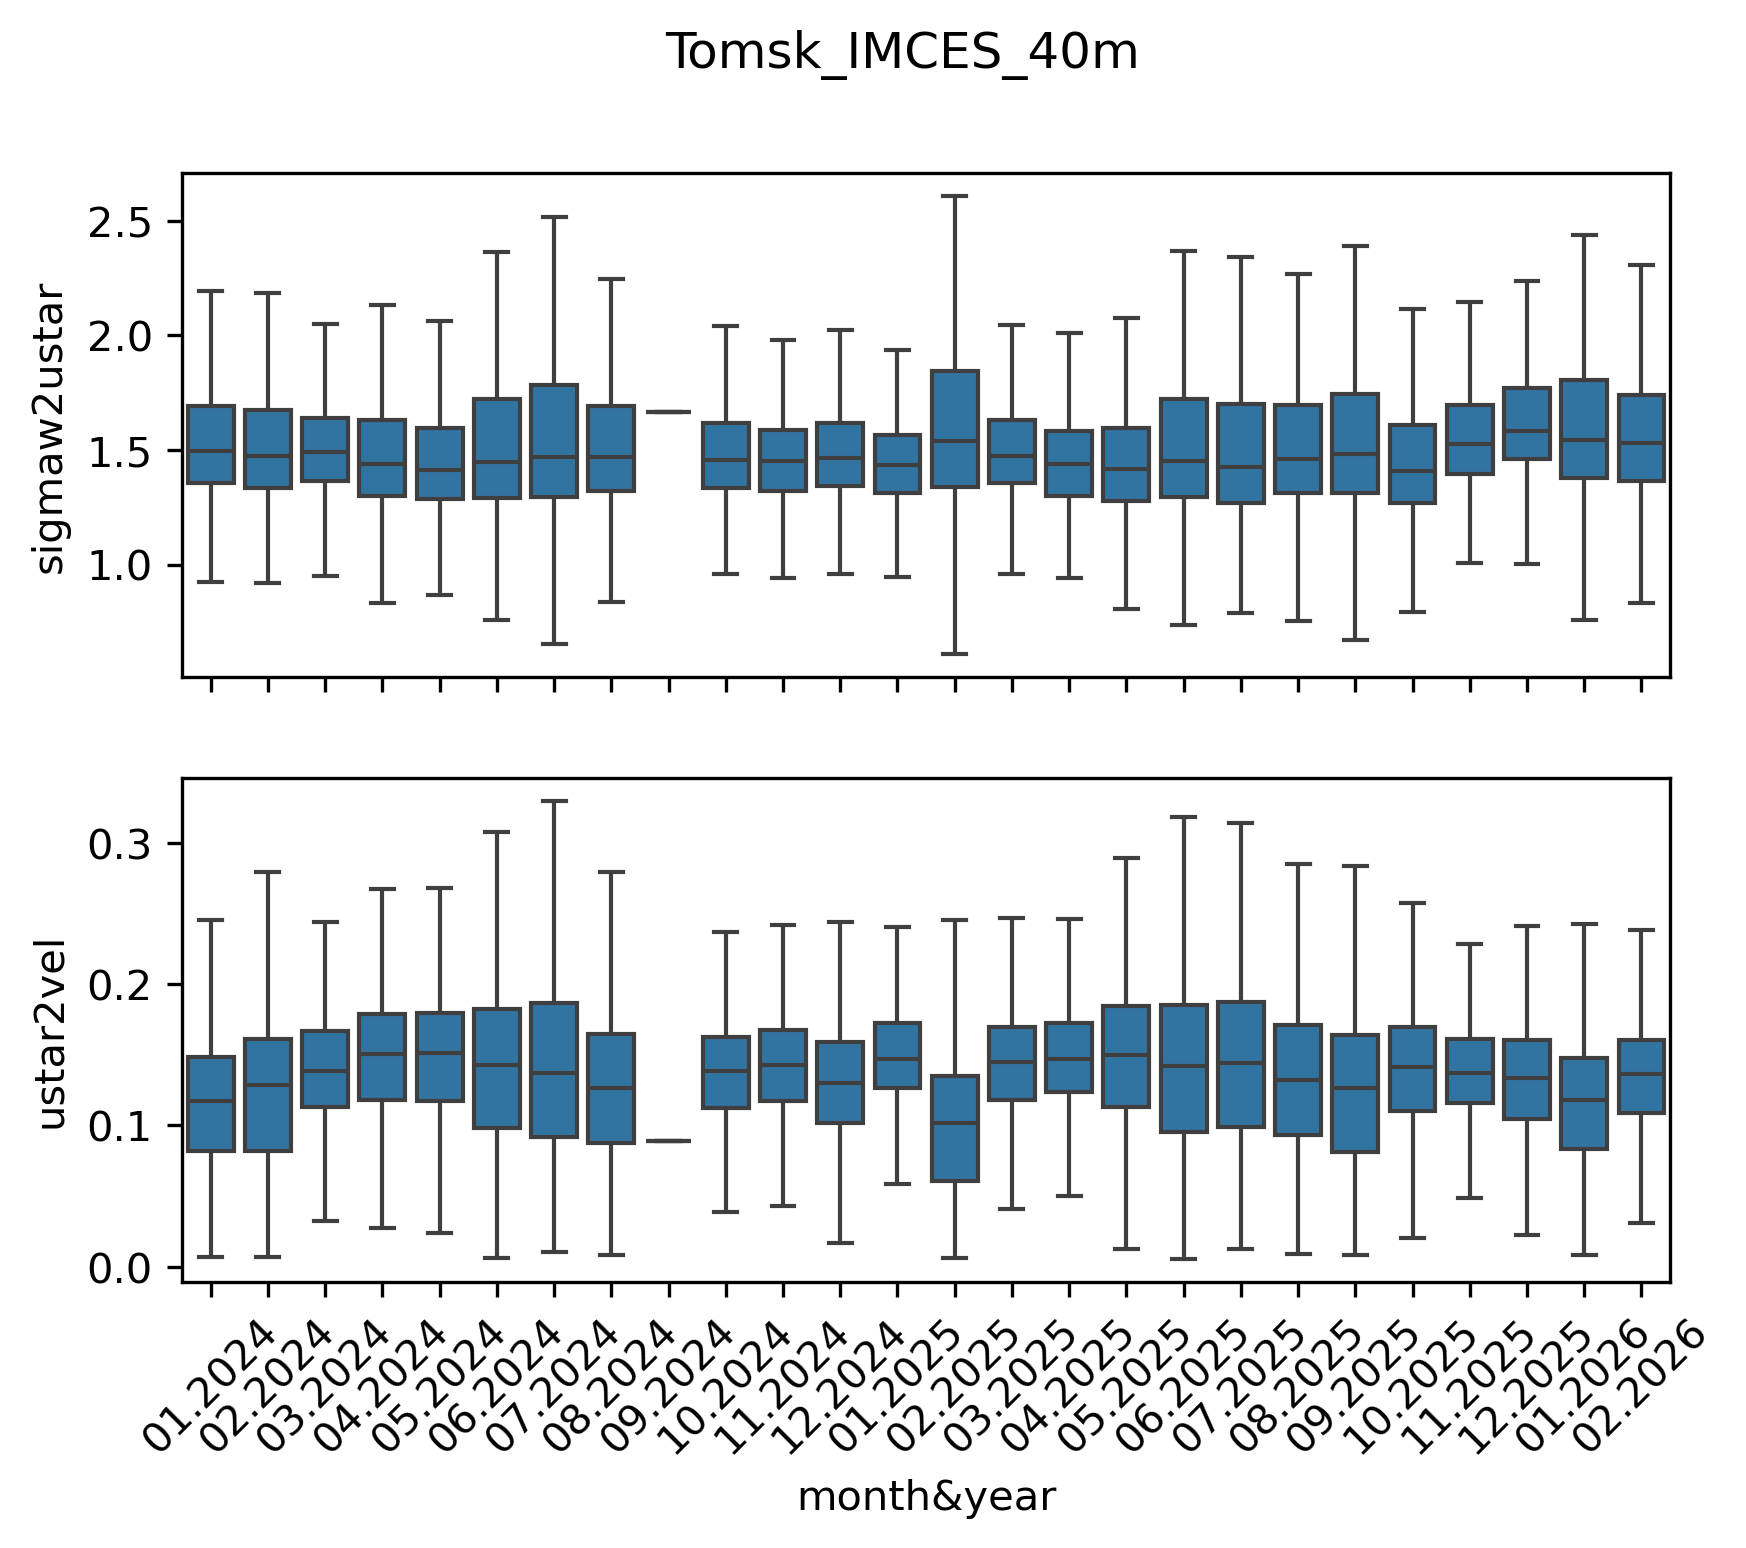

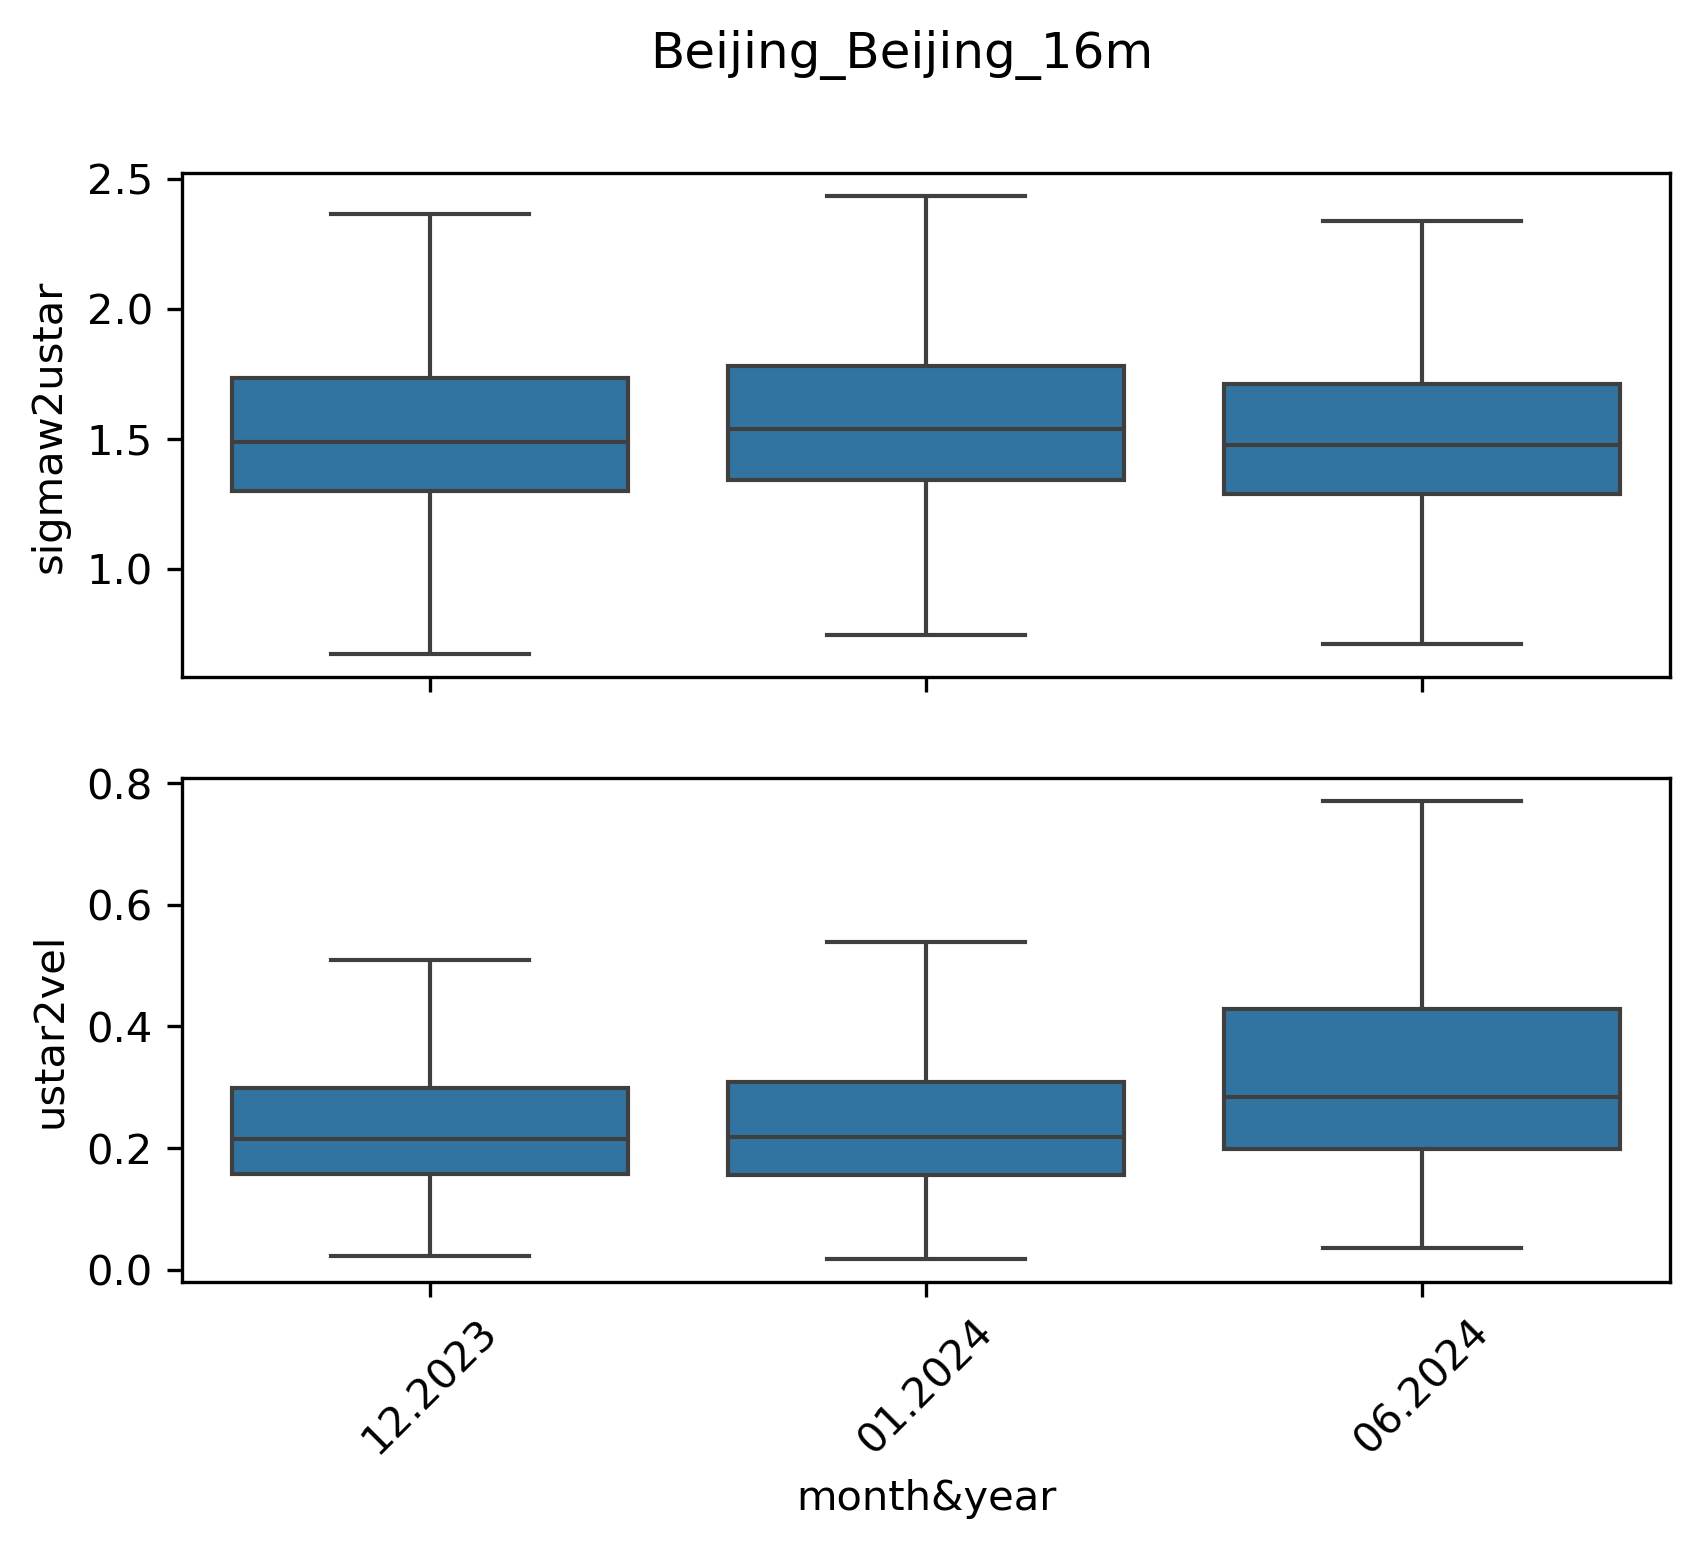

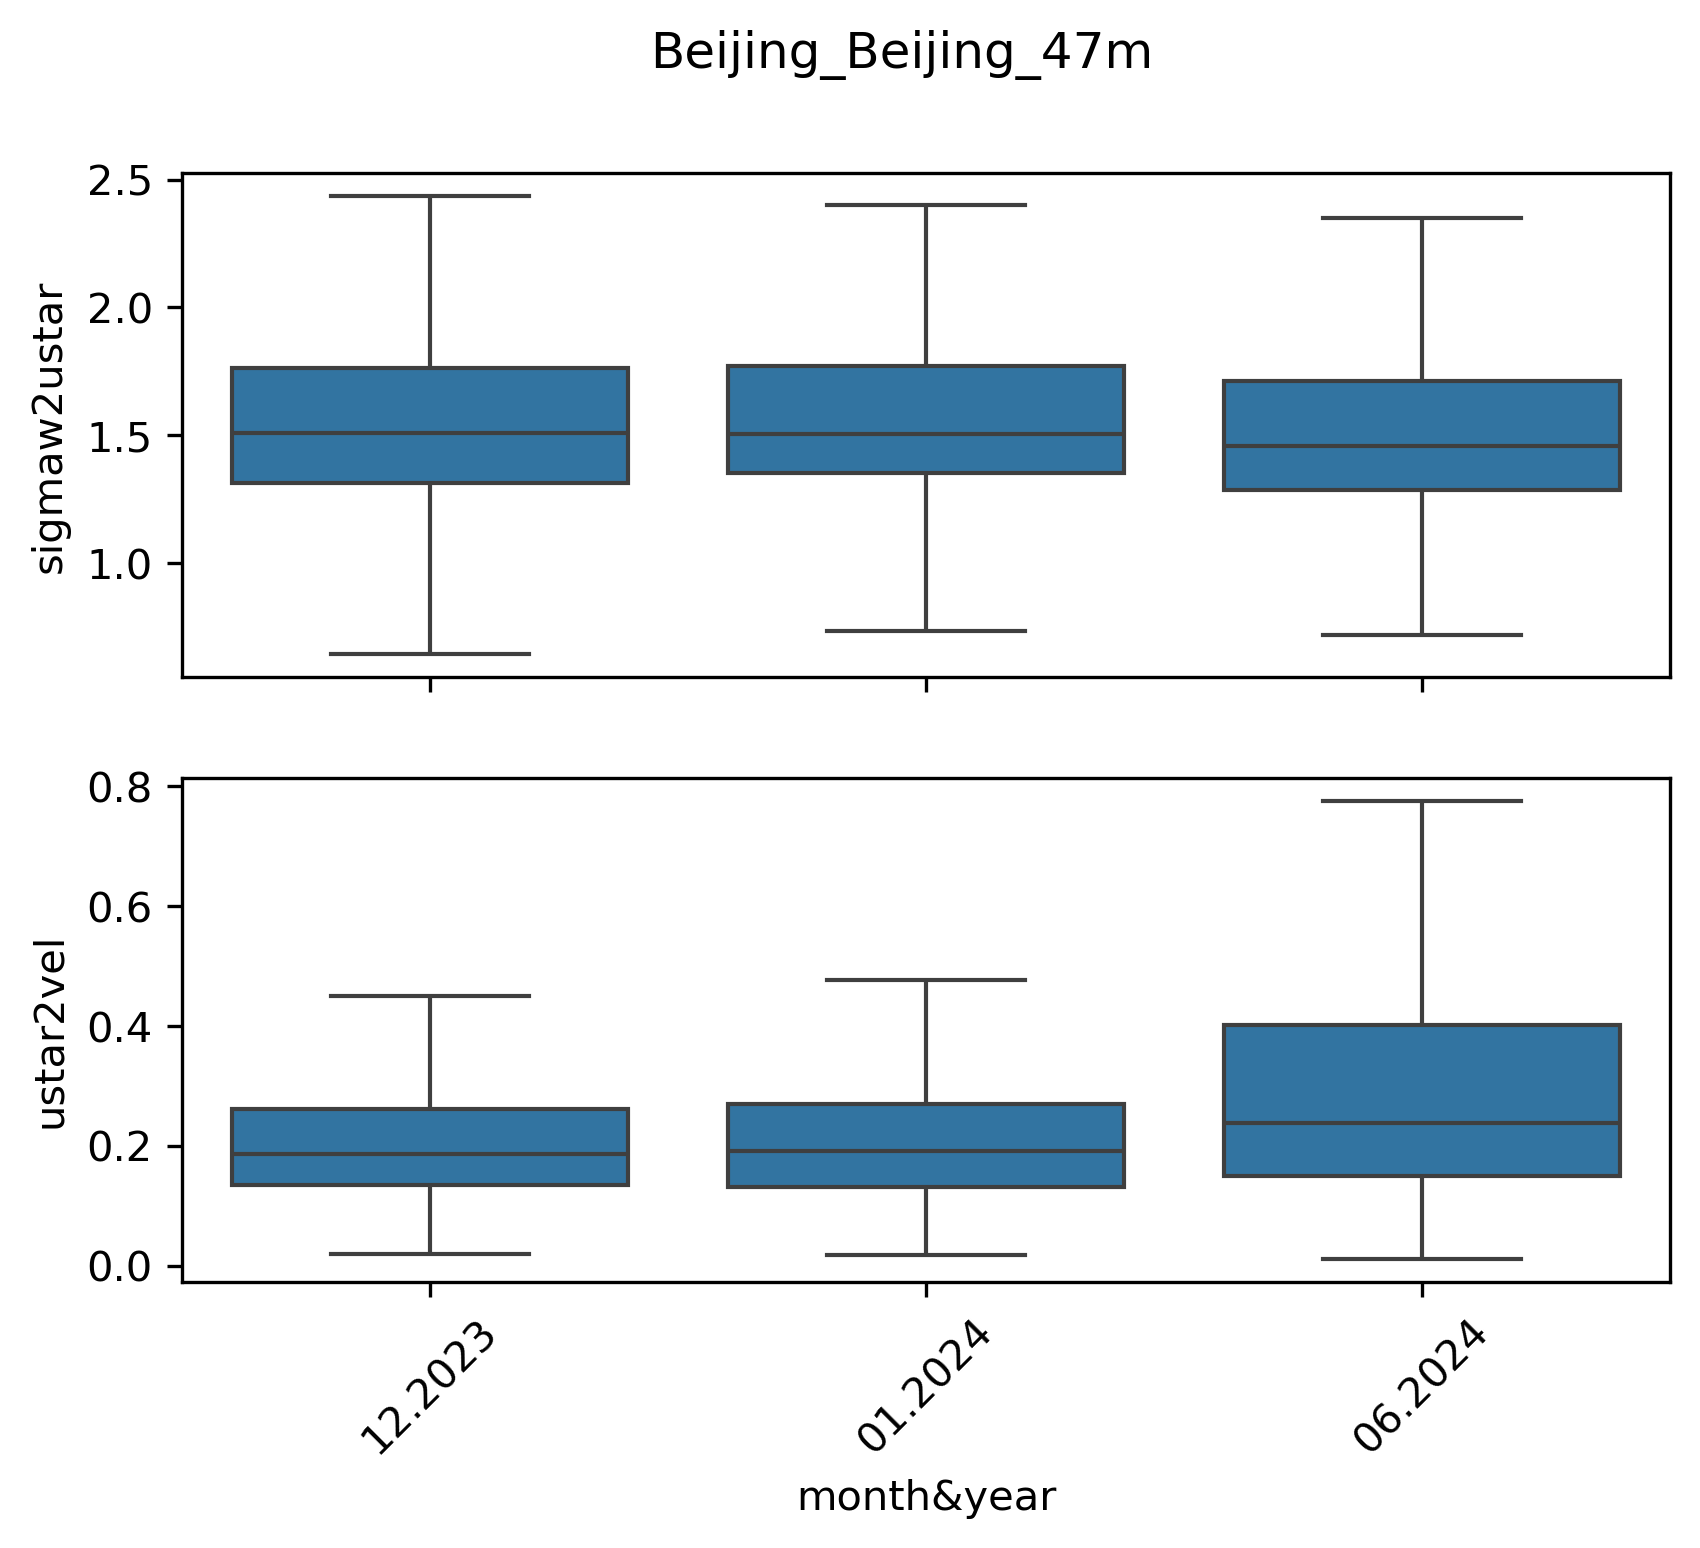

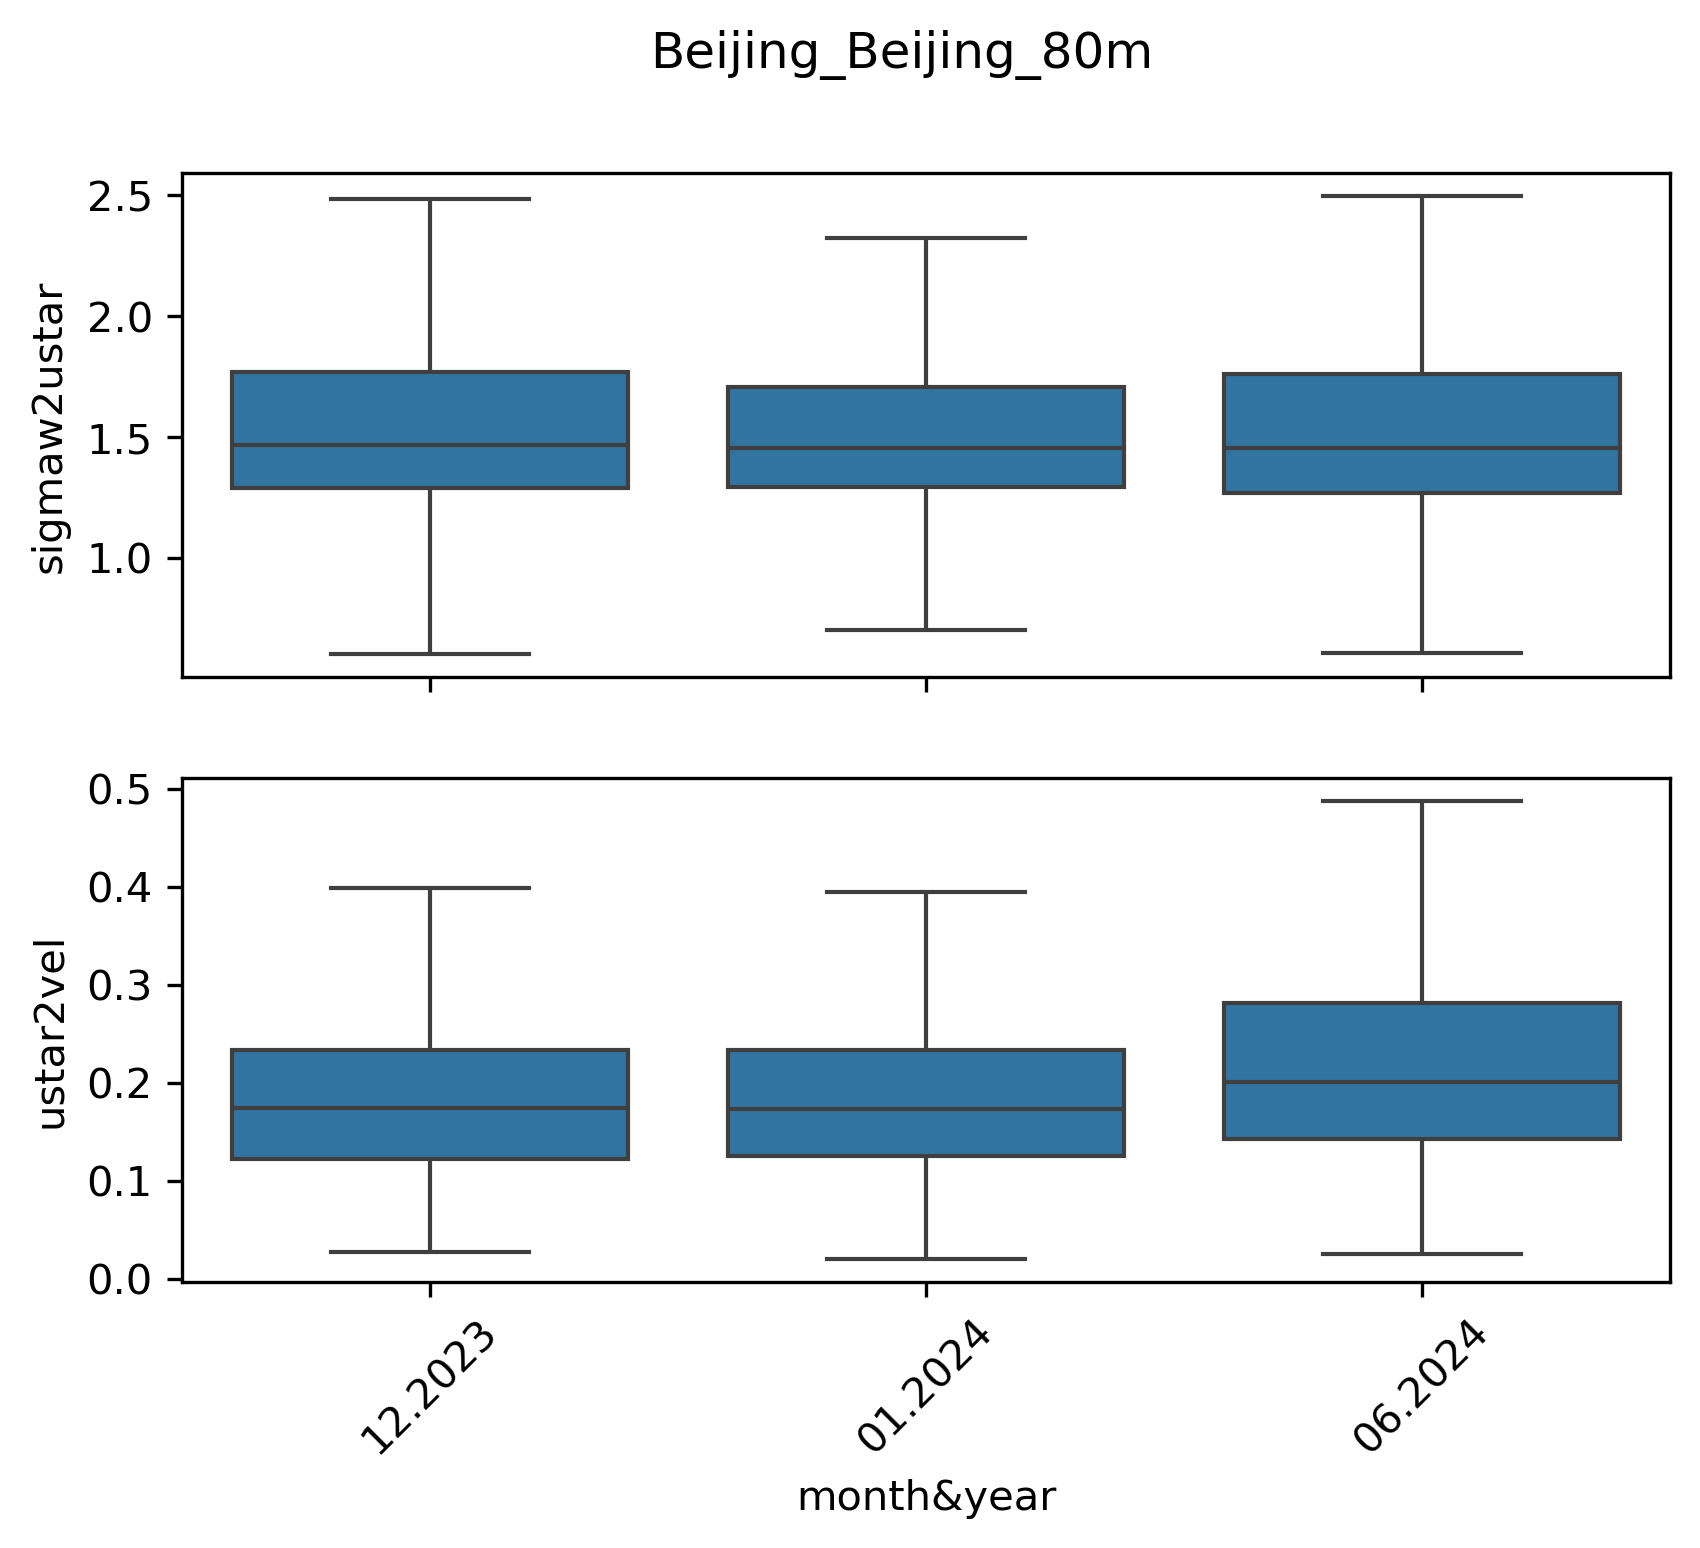

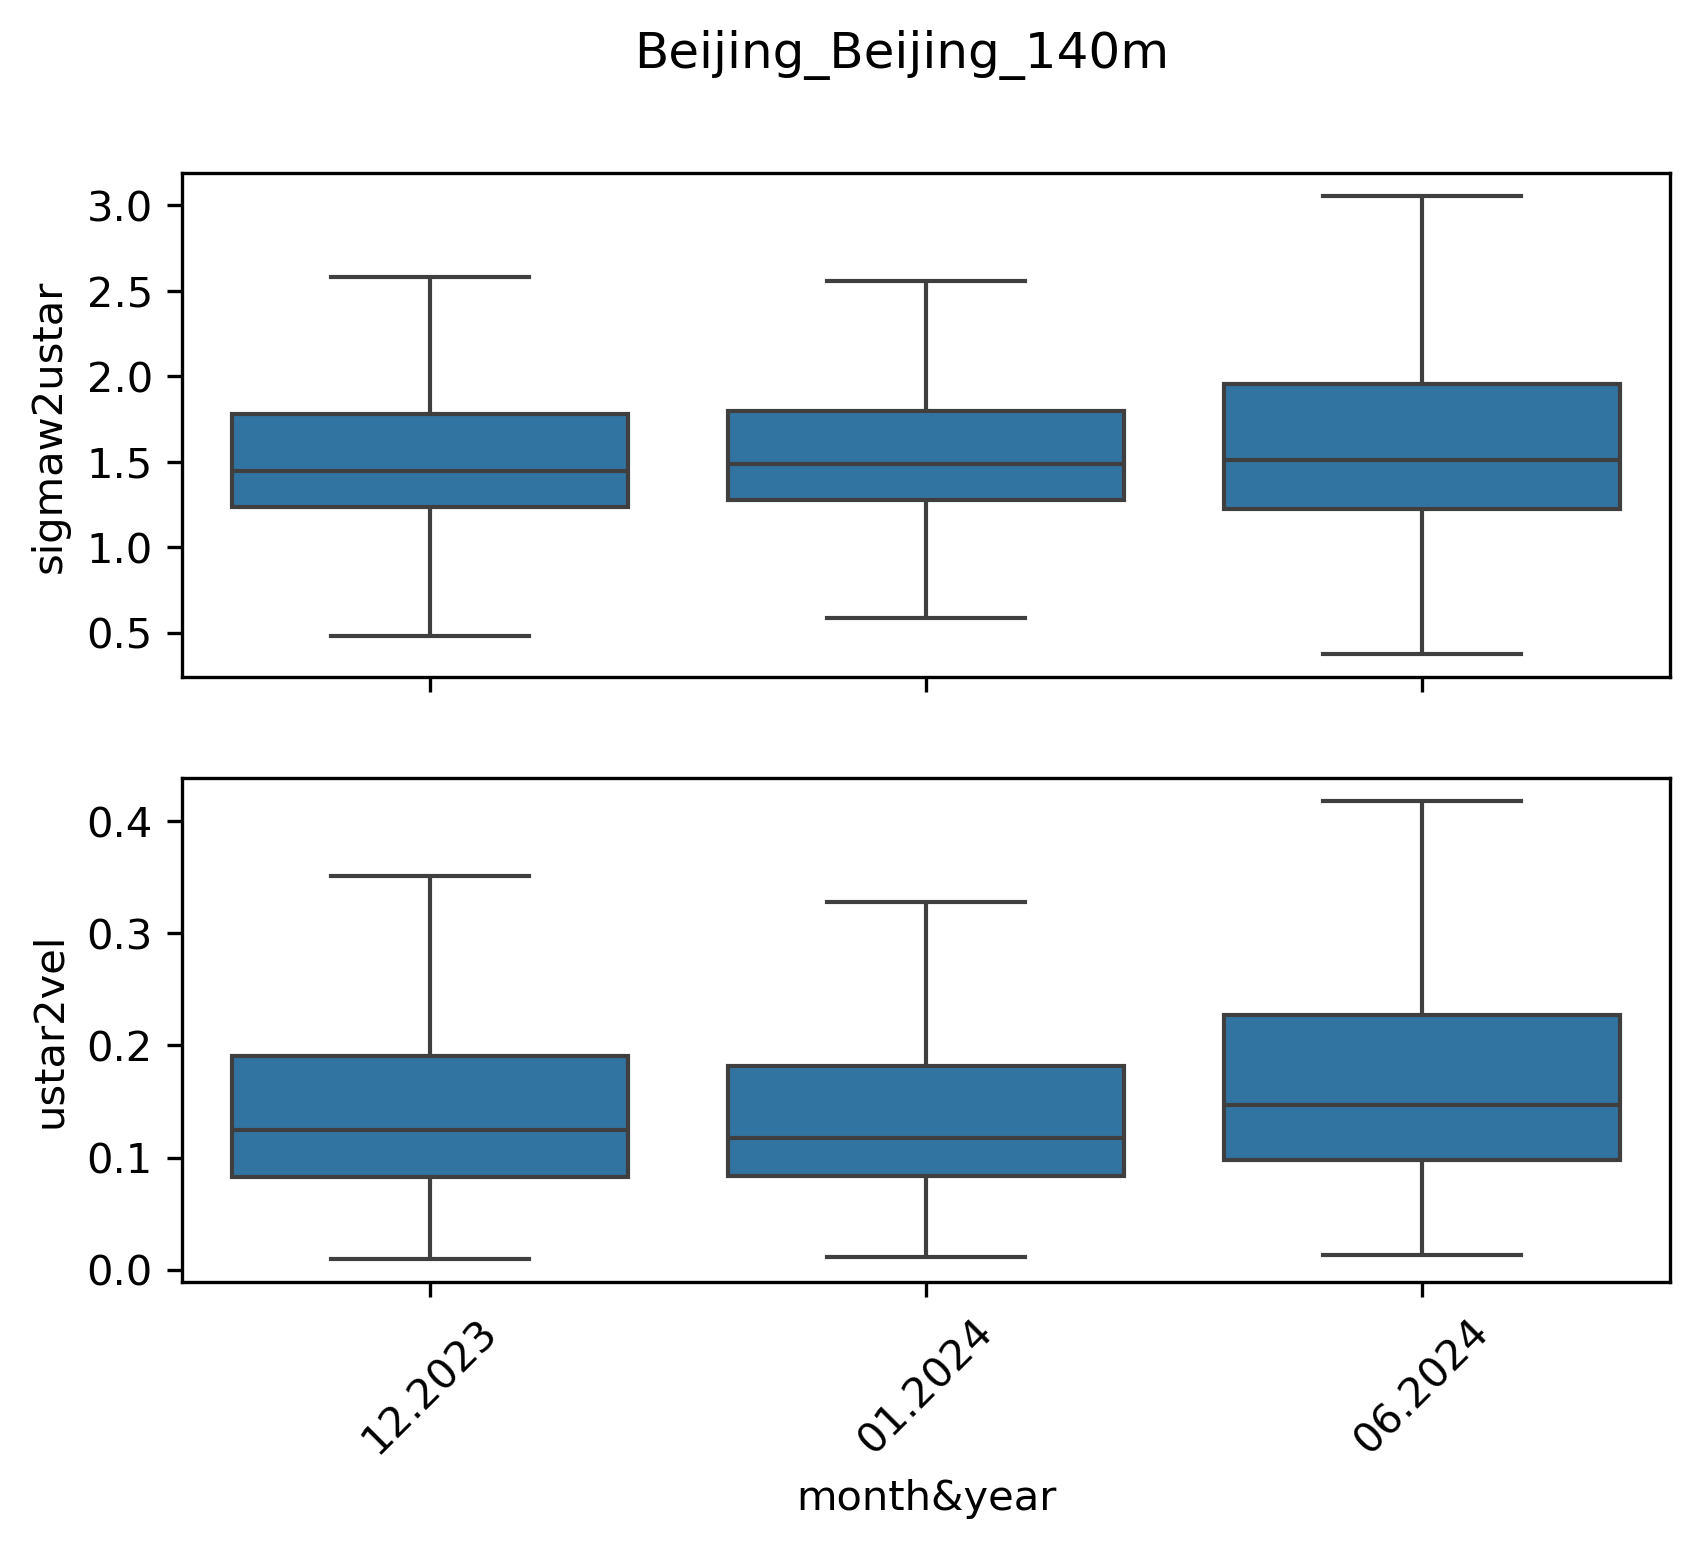

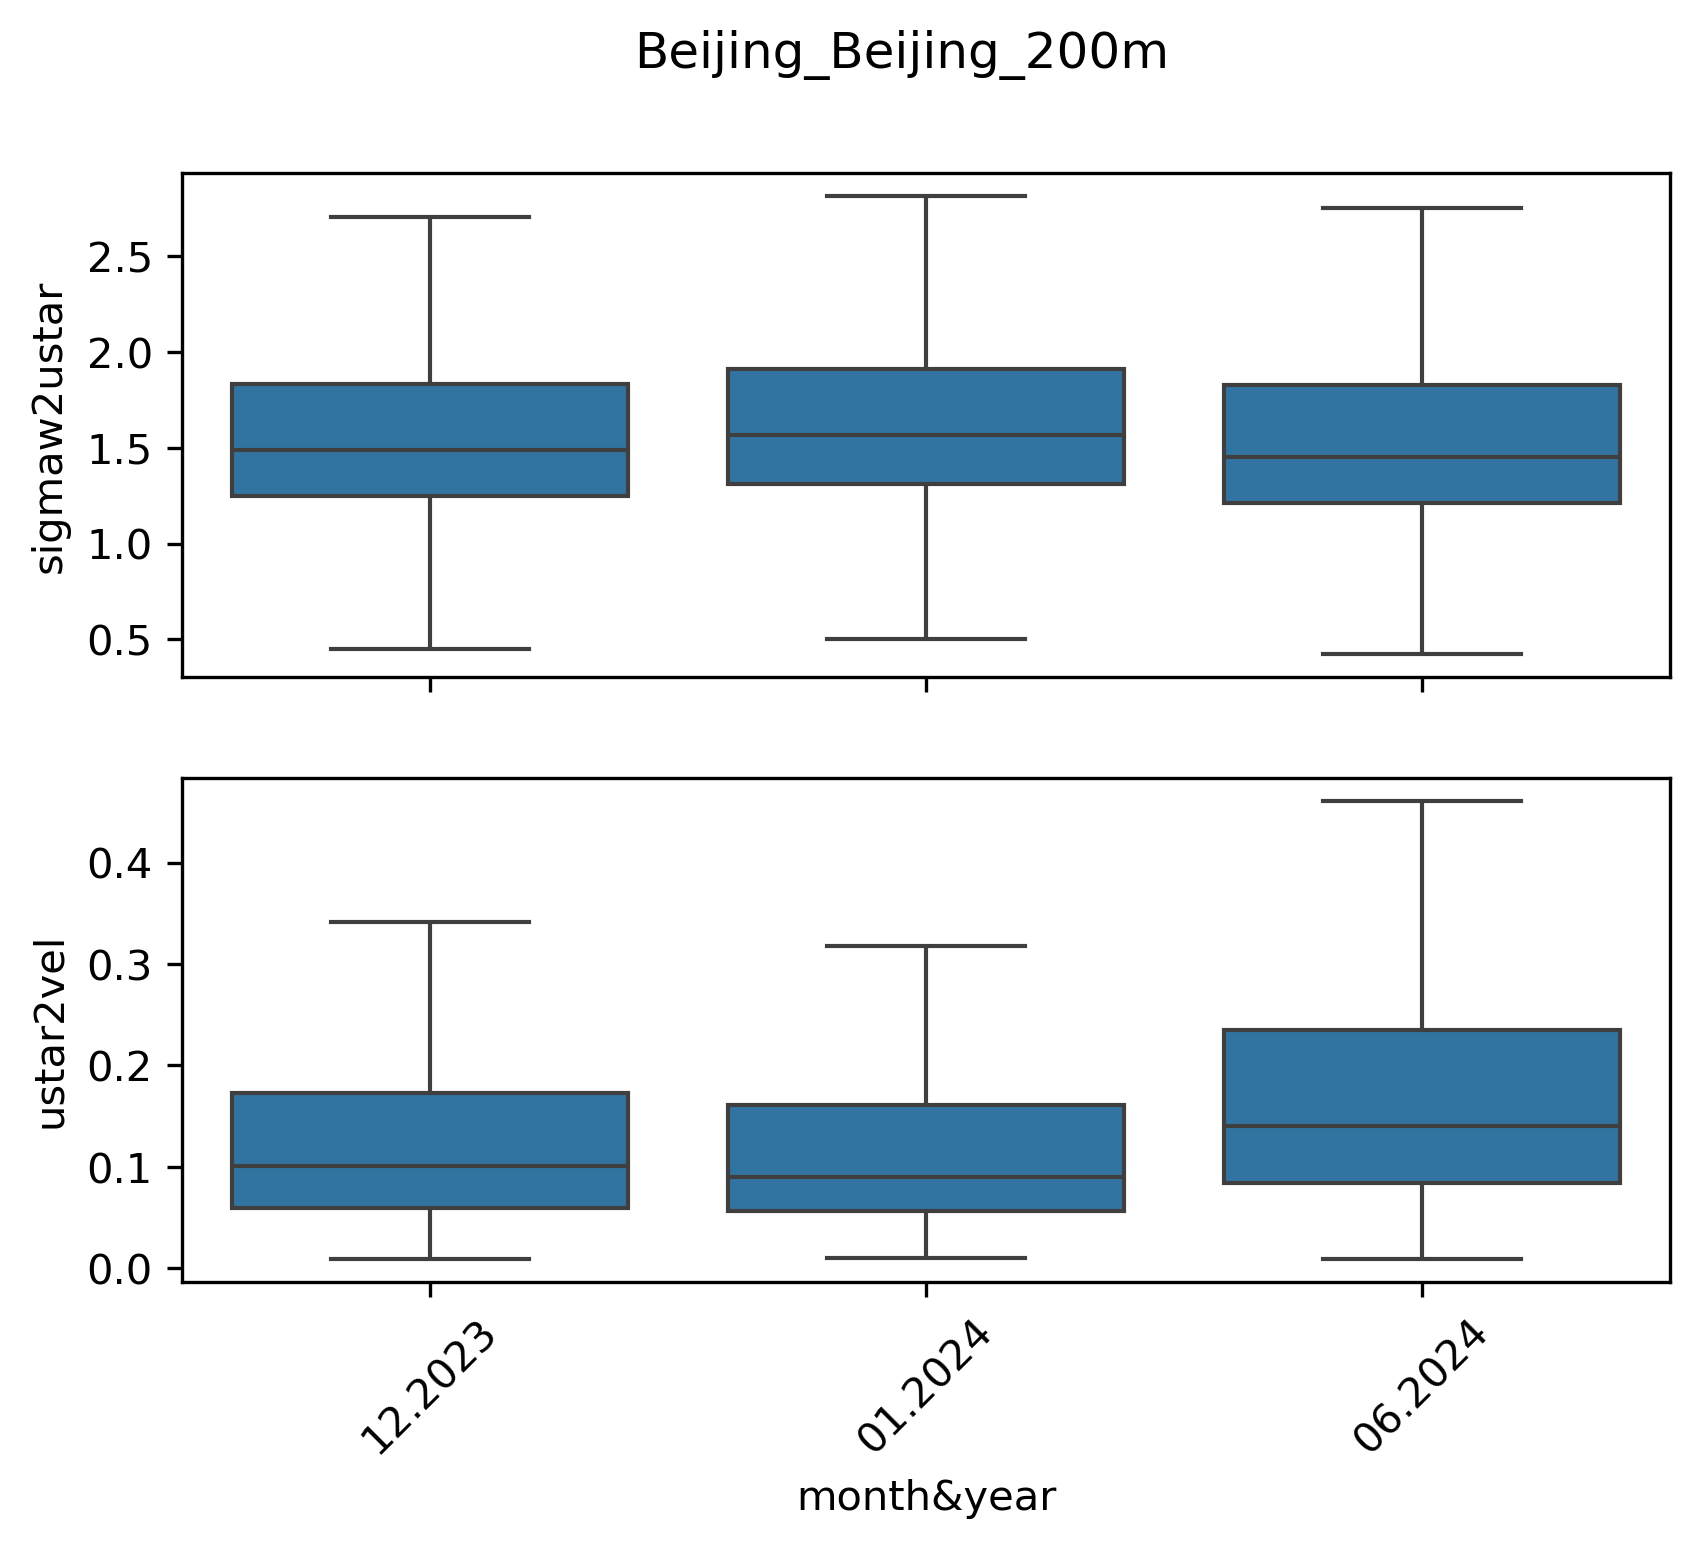

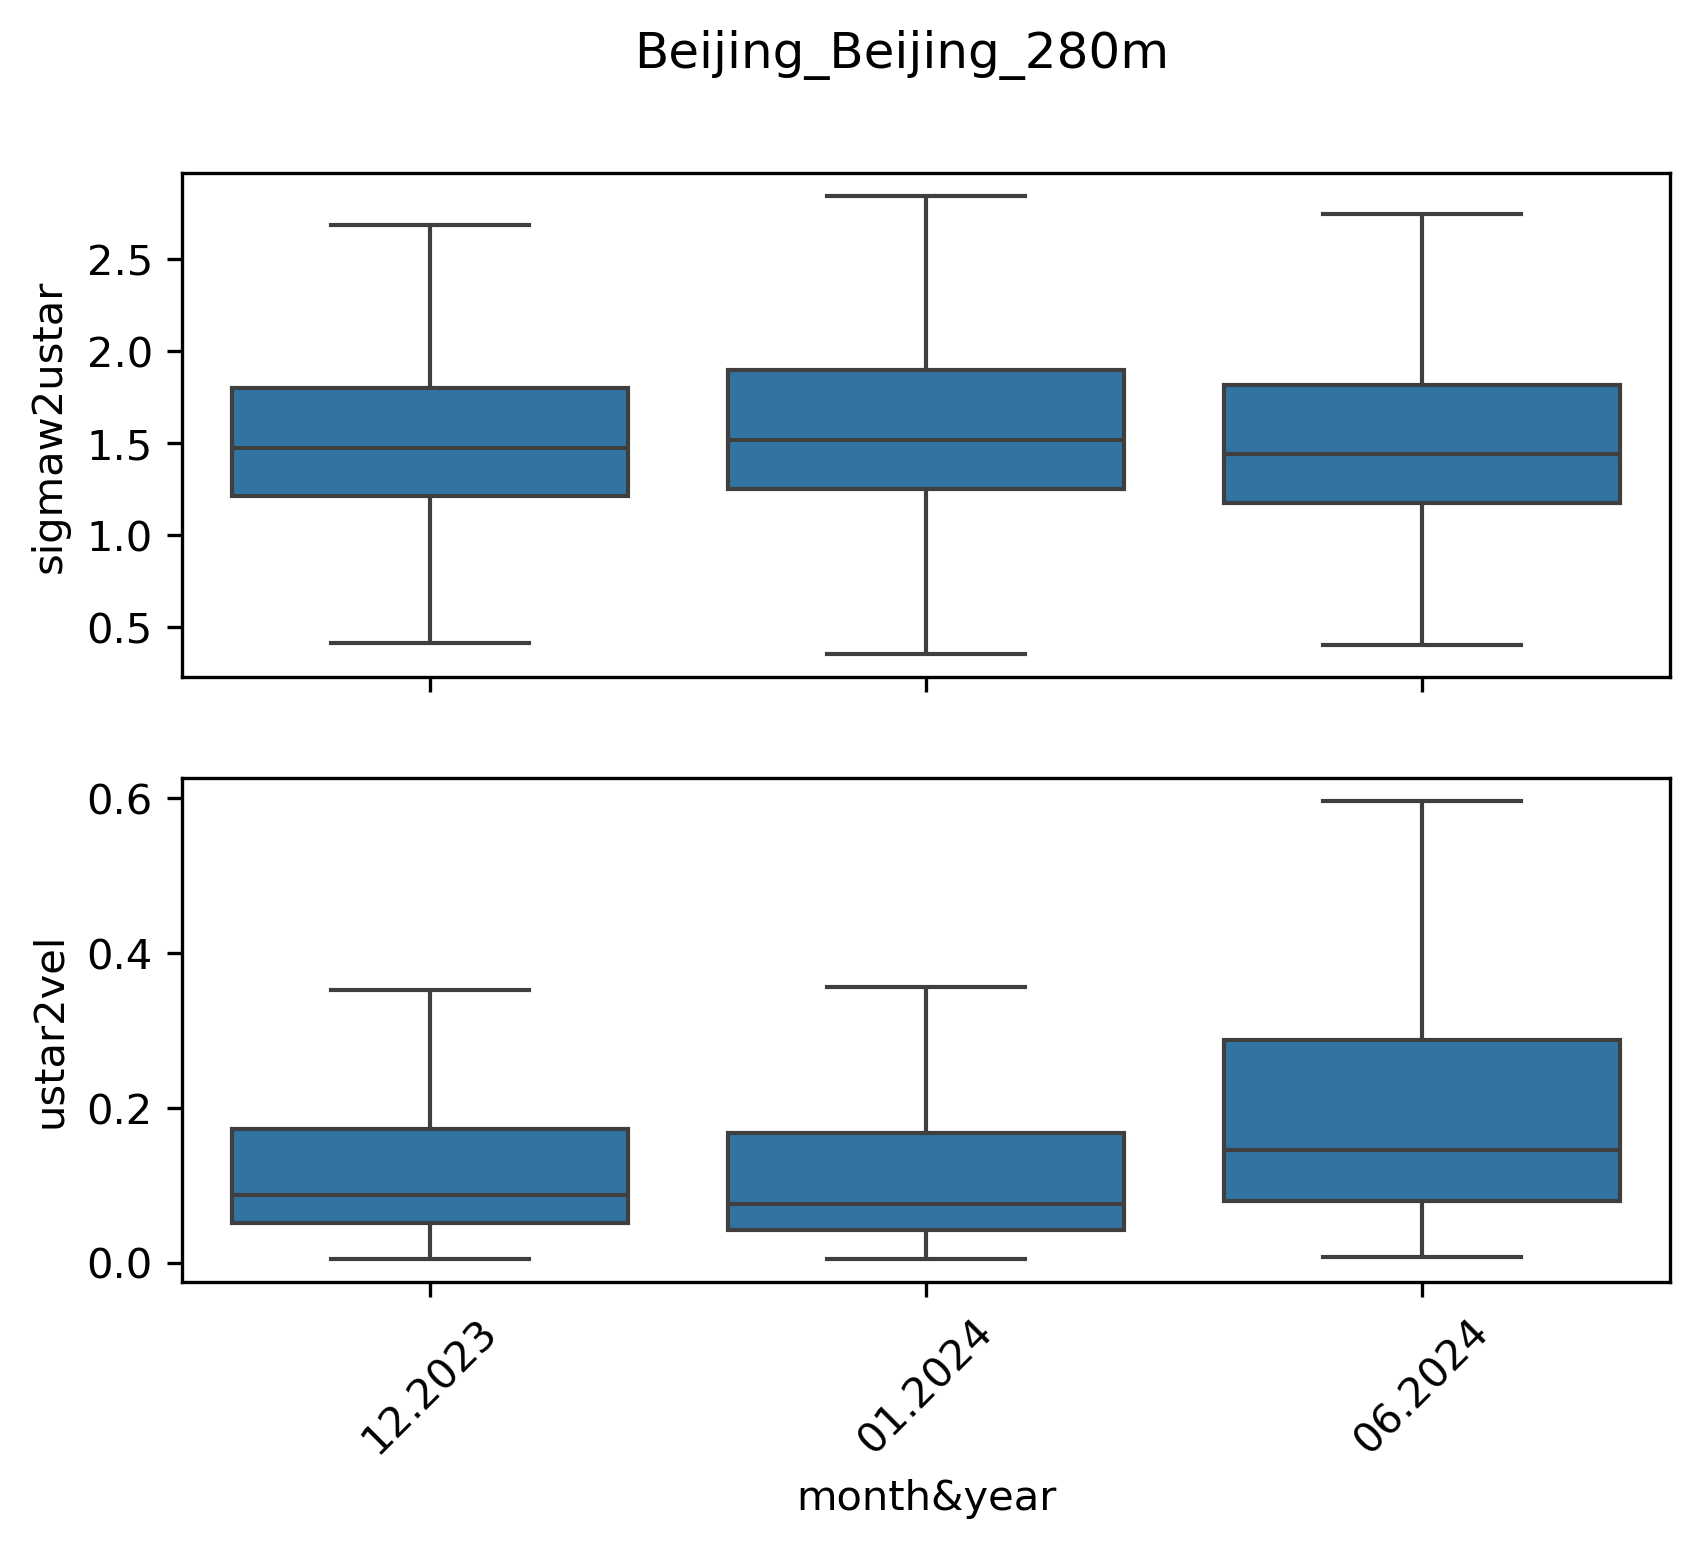

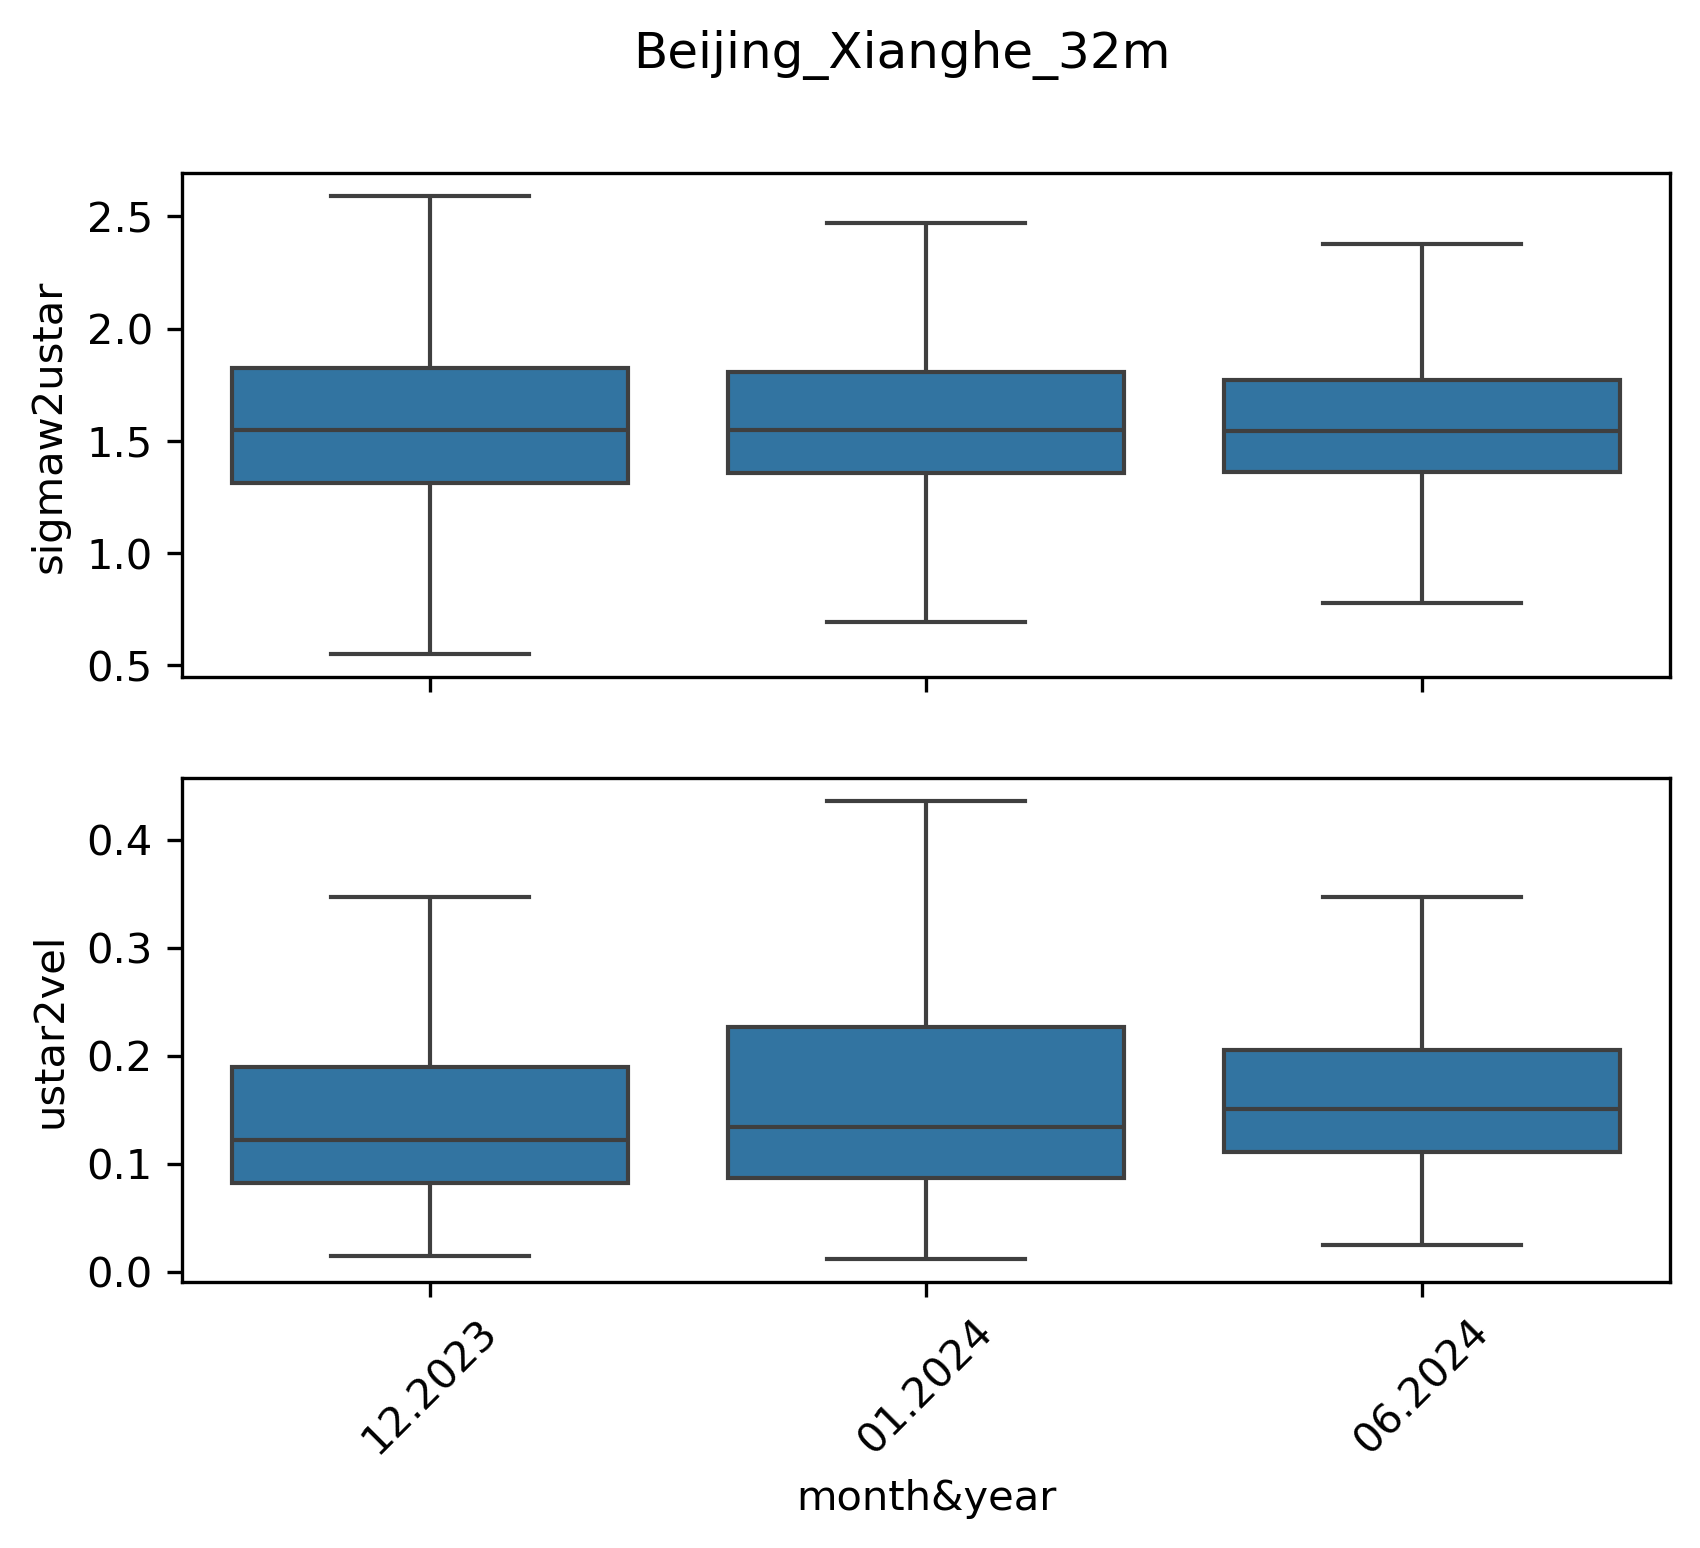

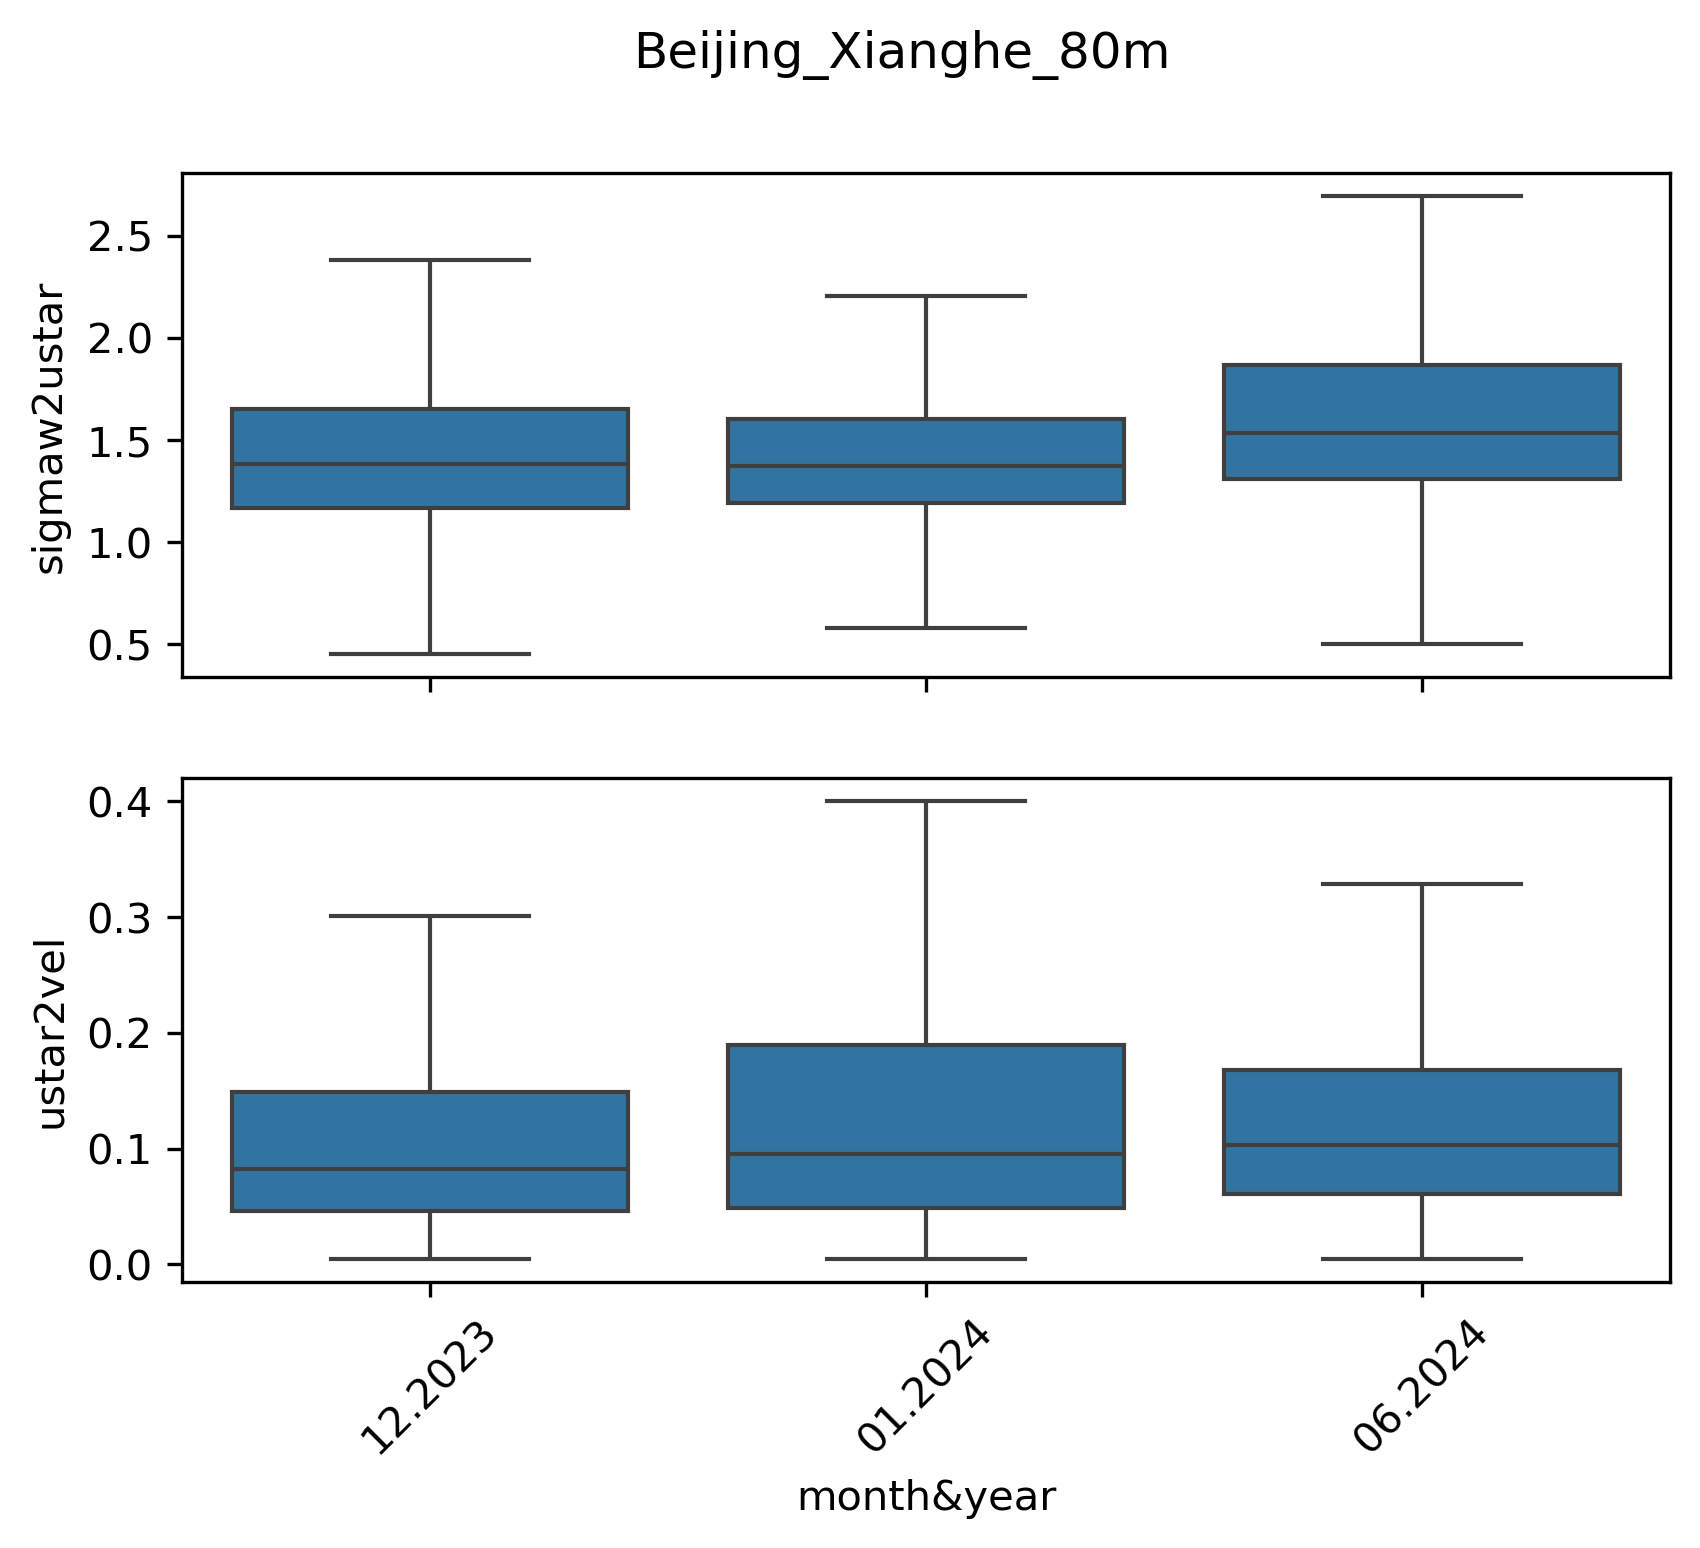

In [4]:
save_dir = 'pics_qc_metrics_boxplots/'
os.makedirs(save_dir, exist_ok=True)

for site in [site for site in df_merged['site'].unique() if 'dummy' not in site]:

    data2draw = df_merged.loc[df_merged['site'] == site, :].copy()
    data2draw['sigmaw2ustar'] = data2draw['Wind_W_std'] / data2draw['Ustar']
    data2draw['ustar2vel'] = data2draw['Ustar'] / data2draw['Wind_vel']
    data2draw['month&year'] = data2draw.index.strftime('%m.%Y')


    fig, ax = plt.subplots(2,1, sharex=True)
    plt.sca (ax[0])
    sns.boxplot(x = data2draw['month&year'], y = data2draw['sigmaw2ustar'], showfliers=False)
    plt.sca (ax[1])
    sns.boxplot(x = data2draw['month&year'], y = data2draw['ustar2vel'], showfliers=False)
    _ = plt.xticks(rotation=45)
    plt.suptitle(site)
    
    plt.savefig(save_dir + site + '.png')
    


In [75]:
color4sites

{'Beijing_Beijing': array([0.83921569, 0.15294118, 0.15686275]),
 'Beijing_Xianghe': array([0.09019608, 0.74509804, 0.81176471]),
 'Moscow_LOD': array([0.12156863, 0.46666667, 0.70588235]),
 'Moscow_MSU': array([1.        , 0.49803922, 0.05490196]),
 'Moscow_ZNS': array([0.17254902, 0.62745098, 0.17254902]),
 'Moscow_dummy': array([0.61960784, 0.85490196, 0.89803922]),
 'Tomsk_BEK': array([0.68235294, 0.78039216, 0.90980392]),
 'Tomsk_IMCES': array([0.54901961, 0.3372549 , 0.29411765]),
 'Tomsk_Oblkom': array([1.        , 0.59607843, 0.58823529]),
 'Tomsk_Voronino': array([0.59607843, 0.8745098 , 0.54117647])}

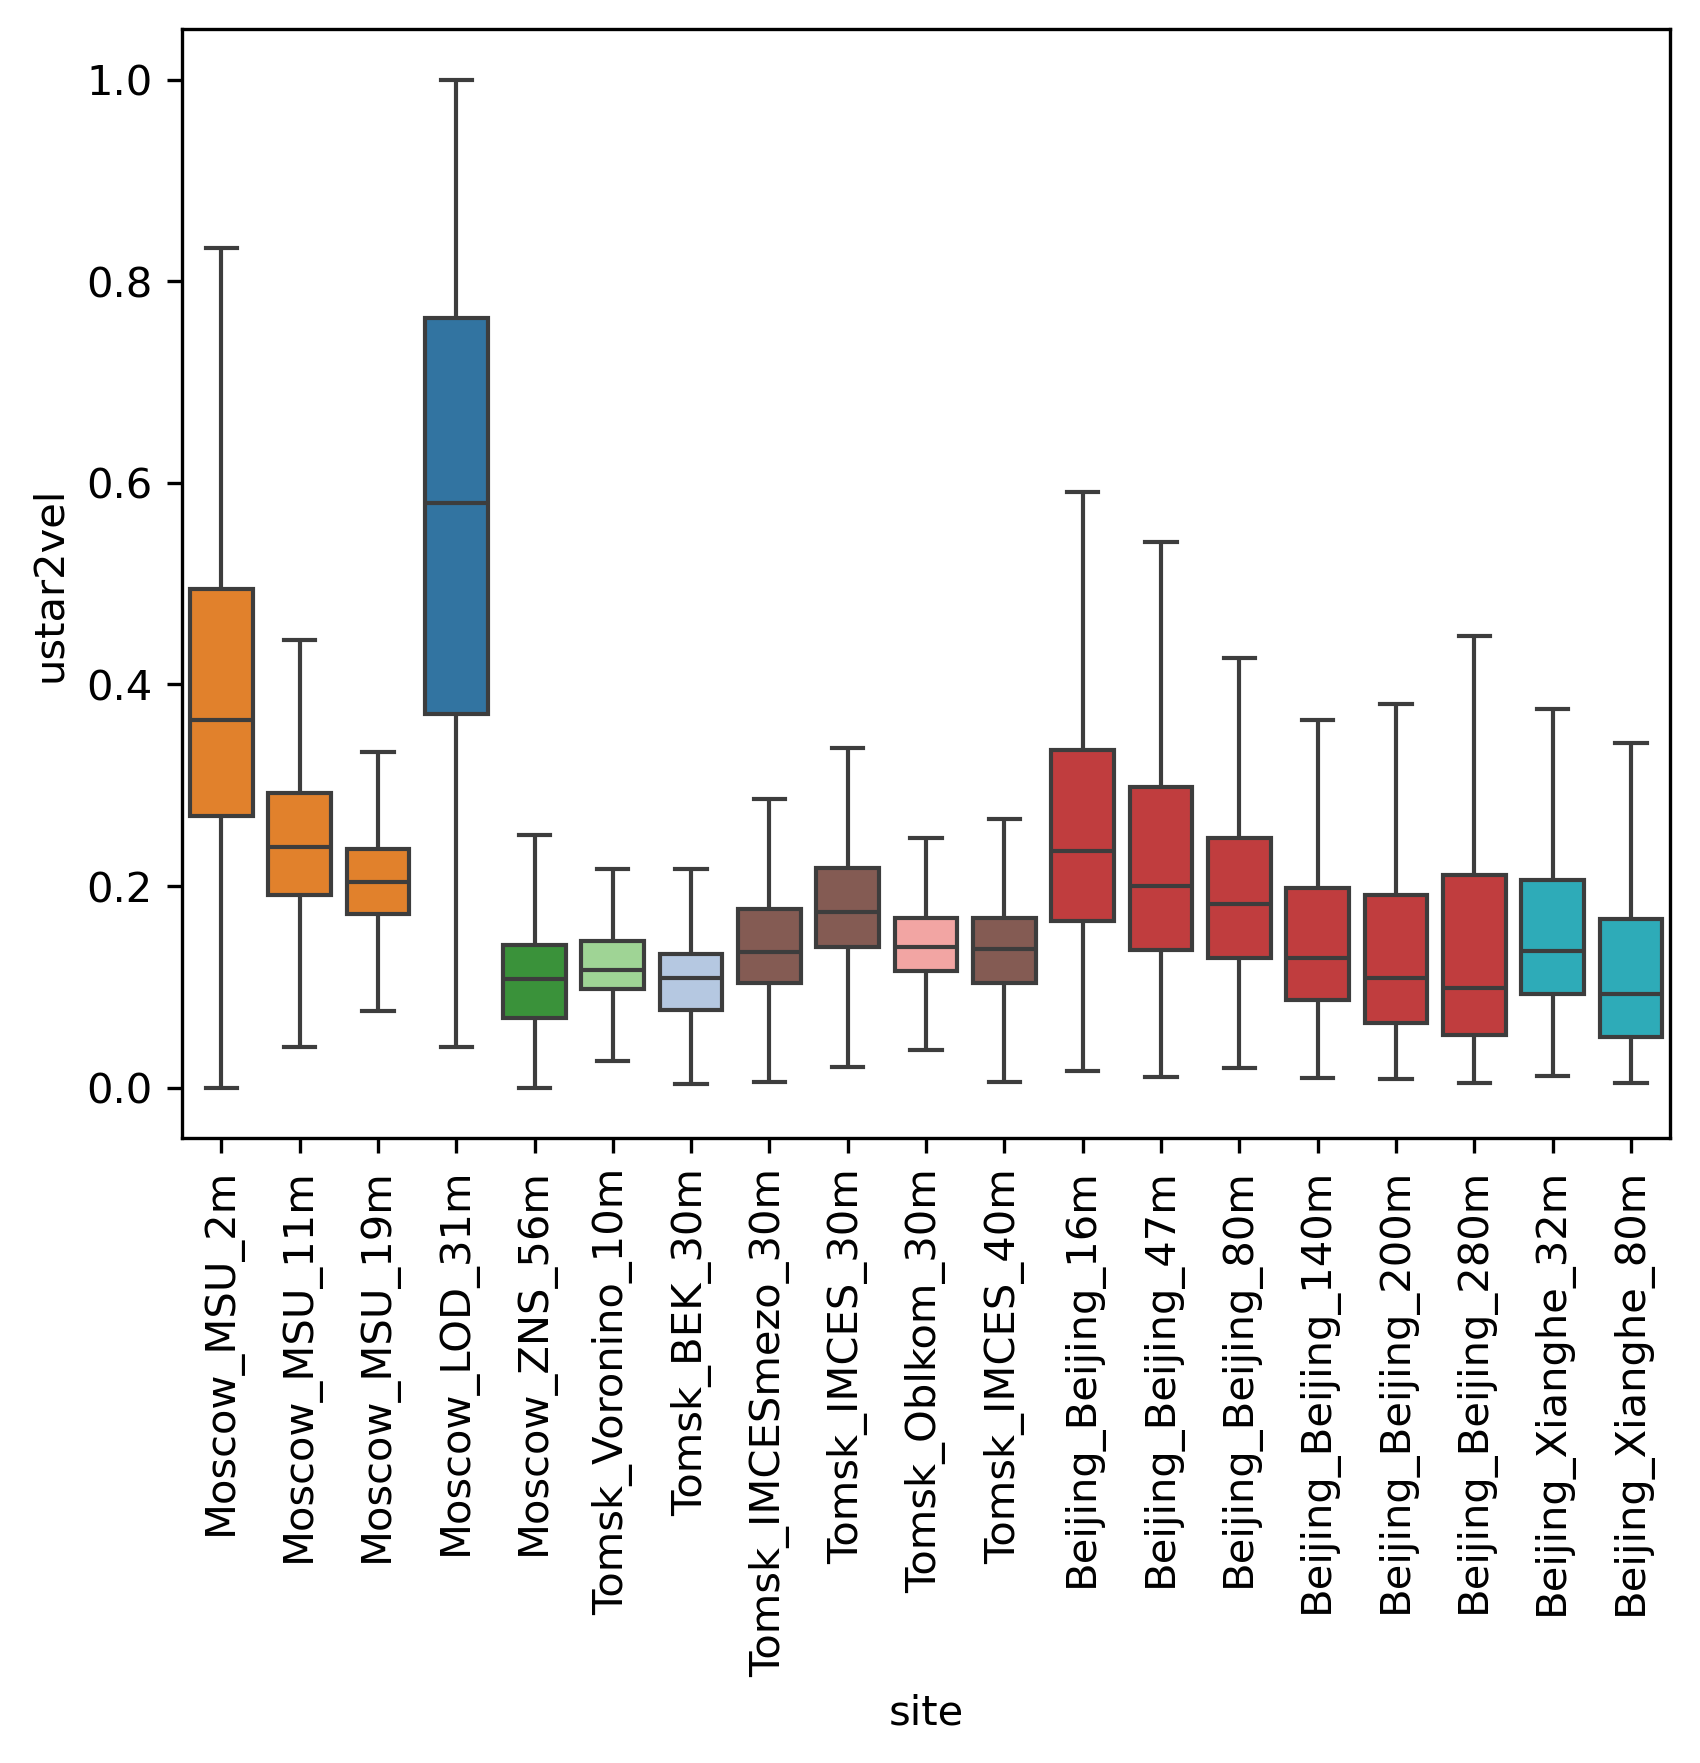

In [ ]:

df2draw = df_merged.copy().reset_index()
df2draw = df2draw.drop(index = df2draw[df2draw['site'] == 'Moscow_dummy_5'].index)

sites = df2draw['site'].unique()
colors2draw = [color4sites['_'.join(s.replace('site = ', '').replace('mezo', '').split('_')[0:-1])] for s in sites]
#df2draw['site'].unique()
df2draw['sigmaw2ustar'] = df2draw['Wind_W_std'] / df2draw['Ustar']
df2draw['ustar2vel'] = df2draw['Ustar'] / df2draw['Wind_vel']
    
sns.boxplot(x = df2draw['site'], y = df2draw['ustar2vel'], hue = df2draw['site'], showfliers=False, palette = colors2draw)
_ = plt.xticks(rotation=90)

plt.axhline(1.25, linestyle='--', color = 'black', zorder=0) #, xmin=0, xmax=1, **kwargs)
